# Clustering Analysis of Single-Cell Feature Data

This notebook explores clustering methods applied to high-content single-cell morphological data. The main goals are to:

- Apply **dimensionality reduction** techniques (PCA, LDA, t-SNE and UMAP) to better visualize and preprocess the data
- Use **unsupervised clustering algorithms** (K-Means, Gaussian Mixture Models, and DBSCAN) to group cells based on morphological similarity
- Compare clustering performance using **silhouette scores**
- Visualize clustering results in 2D space using PCA projections

The data contains numeric features extracted from single-cell images. Each cell is also labeled with its treatment class, which is used for evaluation (not clustering itself).



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import umap
import os
import re

from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from mpl_toolkits.mplot3d import Axes3D
from sklearn.manifold import TSNE

from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import numpy as np
from itertools import combinations

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GroupKFold,
    StratifiedKFold,
    cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder


# Publication-oriented plotting defaults
# Enlarged so text remains readable after reduction in multi-panel figures.
TITLE_FONTSIZE = 24
AXIS_LABEL_FONTSIZE = 22
TICK_FONTSIZE = 18
LEGEND_FONTSIZE = 18
LEGEND_TITLE_FONTSIZE = 19
COLORBAR_LABEL_FONTSIZE = 20
COLORBAR_TICK_FONTSIZE = 17
HEATMAP_ANNOT_FONTSIZE = 16
LINE_WIDTH = 2.6
MARKER_SIZE = 7

sns.set_theme(
    context="paper",
    style="white",
    font_scale=1.0,
    rc={
        "axes.labelsize": AXIS_LABEL_FONTSIZE,
        "axes.titlesize": TITLE_FONTSIZE,
        "axes.titleweight": "bold",
        "legend.fontsize": LEGEND_FONTSIZE,
        "legend.title_fontsize": LEGEND_TITLE_FONTSIZE,
        "xtick.labelsize": TICK_FONTSIZE,
        "ytick.labelsize": TICK_FONTSIZE,
        "figure.titlesize": TITLE_FONTSIZE,
        "figure.dpi": 140,
        "savefig.dpi": 600,
        "axes.linewidth": 1.4,
        "xtick.major.width": 1.3,
        "ytick.major.width": 1.3,
        "xtick.major.size": 6,
        "ytick.major.size": 6,
        "lines.linewidth": LINE_WIDTH,
        "lines.markersize": MARKER_SIZE,
    },
)

plt.rcParams.update({
    "font.size": TICK_FONTSIZE,
    "axes.labelpad": 10,
    "axes.titlepad": 12,
    "legend.frameon": False,
    "savefig.bbox": "tight",
    "savefig.facecolor": "white",
})


RANDOM_STATE = 42
N_PERMUTATIONS = 1000
PERMUTATION_RANDOM_STATE = 2026
MAX_CORRELATION_PAIRS = 50_000
MAX_MAP_QUERIES_PER_STATE = 500
MAX_SHAP_CELLS = 2_000
OUTPUT_DIR = os.path.join(os.getcwd(), "single_cell_publication_outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

STATE_PALETTE = {
    "G0-arrested": "#4CAF50",
    "Proliferative": "#7E57C2",
}

from scipy.stats import mannwhitneyu, pearsonr, spearmanr
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import auc

from sklearn.ensemble import RandomForestClassifier

from sklearn.neighbors import KNeighborsClassifier

from sklearn.covariance import LedoitWolf
from scipy.special import expit

from sklearn.calibration import calibration_curve


/opt/miniconda3/envs/bioimage_scripts/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load the Data



In [ ]:
def apply_publication_font_sizes(
    ax,
    *,
    title_size=TITLE_FONTSIZE,
    label_size=AXIS_LABEL_FONTSIZE,
    tick_size=TICK_FONTSIZE,
    legend_size=LEGEND_FONTSIZE,
):
    """Apply large, consistent fonts to a Matplotlib axis."""
    ax.title.set_fontsize(title_size)
    ax.title.set_fontweight("bold")
    ax.xaxis.label.set_fontsize(label_size)
    ax.yaxis.label.set_fontsize(label_size)
    ax.tick_params(
        axis="both",
        which="major",
        labelsize=tick_size,
        width=1.3,
        length=6,
    )

    legend = ax.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            text.set_fontsize(legend_size)
        if legend.get_title() is not None:
            legend.get_title().set_fontsize(
                LEGEND_TITLE_FONTSIZE
            )

    return ax


In [ ]:
# Load the data
df = pd.read_csv(r'path_csv')
df.head(10)

,Unnamed: 0,Metadata_plate_map_name,Metadata_cell,Metadata_compound,Metadata_concentration_uM,Metadata_control_type,Metadata_Plate,Metadata_QCFlag,Metadata_QCFlag.1,Metadata_Site,...,Cells_Texture_InfoMeas2_AOPI_20_03_256,Cells_Texture_InfoMeas2_AOPI_5_02_256,Cells_Texture_InverseDifferenceMoment_AOGFP_20_01_256,Cells_Texture_InverseDifferenceMoment_AOGFP_20_03_256,Cells_Texture_InverseDifferenceMoment_AOPI_20_00_256,Cells_Texture_InverseDifferenceMoment_AOPI_20_01_256,Cells_Texture_InverseDifferenceMoment_AOPI_20_02_256,Cells_Texture_InverseDifferenceMoment_AOPI_20_03_256,Cells_Texture_SumEntropy_AOPI_20_01_256,Cells_Texture_SumVariance_AOGFP_20_01_256
0,0,layout_day2,MCF7,CoCl2,300,trt,240321_153415_Plate_1_,0,0,1,...,-0.784285,-0.818853,0.360936,0.189911,-0.203339,2.245335,0.371839,-0.831308,-0.487857,0.144331
1,1,layout_day2,MCF7,CoCl2,300,trt,240321_153415_Plate_1_,0,0,1,...,-0.593191,-1.013499,-0.285007,-1.075082,0.208947,1.387274,0.670347,0.072042,-1.027127,0.489534
2,2,layout_day2,MCF7,CoCl2,300,trt,240321_153415_Plate_1_,0,0,1,...,0.544484,-0.219330,-0.819264,-1.605002,-1.312732,-1.197604,-1.252892,-1.310890,0.132235,1.903658
3,3,layout_day2,MCF7,CoCl2,300,trt,240321_153415_Plate_1_,0,0,1,...,-1.195544,-5.192903,0.593029,-0.754001,-0.058159,0.853746,-0.891693,0.211505,-0.540743,1.083488
4,4,layout_day2,MCF7,CoCl2,300,trt,240321_153415_Plate_1_,0,0,1,...,-1.624756,-1.830124,-0.287991,-1.059367,1.297655,0.275606,-0.115876,0.645451,-1.604020,0.798873
5,5,layout_day2,MCF7,CoCl2,300,trt,240321_153415_Plate_1_,0,0,1,...,0.385685,0.023922,-0.869929,0.309795,-0.375445,-0.559070,0.786707,0.331577,0.337986,3.690246
6,6,layout_day2,MCF7,CoCl2,300,trt,240321_153415_Plate_1_,0,0,1,...,-1.654845,-0.293506,1.058090,0.266418,0.907403,2.515308,1.840100,1.329503,-1.157675,3.395043
7,7,layout_day2,MCF7,CoCl2,300,trt,240321_153415_Plate_1_,0,0,1,...,0.101792,-1.575609,-1.513773,1.353132,-0.571557,-0.902060,-0.149902,1.385582,-1.611225,-0.451879
8,8,layout_day2,MCF7,CoCl2,300,trt,240321_153415_Plate_1_,0,0,1,...,-1.518310,-0.179418,1.470649,2.540990,2.604120,2.943804,2.572439,3.091443,-1.515166,1.055383
9,9,layout_day2,MCF7,CoCl2,300,trt,240321_153415_Plate_1_,0,0,1,...,-2.526044,-2.423584,2.174500,2.818794,2.972256,3.925936,2.610547,3.587233,-2.306669,0.811014


In [3]:
df = df.dropna(axis=1)

In [4]:
# Substitui valores na coluna Metadata_compound
df['Metadata_compound'] = df['Metadata_compound'].replace({
    'CoCl2': 'G0-arrested',
    'Non-treated': 'Proliferative'
})


In [5]:
df = df.drop(columns=[col for col in df.columns if "Unnamed" in col])

In [6]:
df

,Metadata_plate_map_name,Metadata_cell,Metadata_compound,Metadata_concentration_uM,Metadata_control_type,Metadata_Plate,Metadata_QCFlag,Metadata_QCFlag.1,Metadata_Site,Metadata_Well,...,Cells_Texture_InfoMeas2_AOPI_20_03_256,Cells_Texture_InfoMeas2_AOPI_5_02_256,Cells_Texture_InverseDifferenceMoment_AOGFP_20_01_256,Cells_Texture_InverseDifferenceMoment_AOGFP_20_03_256,Cells_Texture_InverseDifferenceMoment_AOPI_20_00_256,Cells_Texture_InverseDifferenceMoment_AOPI_20_01_256,Cells_Texture_InverseDifferenceMoment_AOPI_20_02_256,Cells_Texture_InverseDifferenceMoment_AOPI_20_03_256,Cells_Texture_SumEntropy_AOPI_20_01_256,Cells_Texture_SumVariance_AOGFP_20_01_256
0,layout_day2,MCF7,G0-arrested,300,trt,240321_153415_Plate_1_,0,0,1,D2,...,-0.784285,-0.818853,0.360936,0.189911,-0.203339,2.245335,0.371839,-0.831308,-0.487857,0.144331
1,layout_day2,MCF7,G0-arrested,300,trt,240321_153415_Plate_1_,0,0,1,D2,...,-0.593191,-1.013499,-0.285007,-1.075082,0.208947,1.387274,0.670347,0.072042,-1.027127,0.489534
2,layout_day2,MCF7,G0-arrested,300,trt,240321_153415_Plate_1_,0,0,1,D2,...,0.544484,-0.219330,-0.819264,-1.605002,-1.312732,-1.197604,-1.252892,-1.310890,0.132235,1.903658
3,layout_day2,MCF7,G0-arrested,300,trt,240321_153415_Plate_1_,0,0,1,D2,...,-1.195544,-5.192903,0.593029,-0.754001,-0.058159,0.853746,-0.891693,0.211505,-0.540743,1.083488
4,layout_day2,MCF7,G0-arrested,300,trt,240321_153415_Plate_1_,0,0,1,D2,...,-1.624756,-1.830124,-0.287991,-1.059367,1.297655,0.275606,-0.115876,0.645451,-1.604020,0.798873
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11854,layout_day3,MCF7,Proliferative,0,negcon,240404_134523_Plate_1_,0,0,9,G11,...,-2.043553,-8.906042,-0.779926,-0.029941,1.124369,0.730808,0.221928,1.541399,-2.745731,-0.464501
11855,layout_day3,MCF7,Proliferative,0,negcon,240404_134523_Plate_1_,0,0,9,G11,...,0.714677,-0.030654,0.081973,-0.033363,-0.490707,-0.498291,-0.293124,-0.368292,0.945287,-0.016125
11856,layout_day3,MCF7,Proliferative,0,negcon,240404_134523_Plate_1_,0,0,9,G11,...,-0.161168,0.284097,1.003780,0.393734,2.295109,2.094126,2.259898,1.463100,-1.422879,-0.246328
11857,layout_day3,MCF7,Proliferative,0,negcon,240404_134523_Plate_1_,0,0,9,G11,...,1.797984,1.433138,0.580059,-0.812526,-1.124554,-0.759304,-1.254906,-0.504583,2.259217,1.153706


In [7]:
column = 'Metadata_compound'

# Descobre a menor quantidade de amostras entre as classes
min_count = df[column].value_counts().min()

# Faz o undersampling: seleciona min_count amostras de cada classe
df = df.groupby(column, group_keys=False).apply(lambda x: x.sample(min_count, random_state=42))


/var/folders/xc/x2b6cmd93rbcjw3gmr43k0kc0000gn/T/ipykernel_72966/3100141159.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby(column, group_keys=False).apply(lambda x: x.sample(min_count, random_state=42))


## Preprocessing and Feature Selection

We select only the numeric features from the dataset, excluding the label column (`label`) which is not used as input for clustering. The `class` column is stored separately for evaluation purposes.

To ensure consistency across features, we:
- Drop rows with missing values
- Standardize the features using `StandardScaler` to have zero mean and unit variance

We also compute the variance of each numeric feature to identify those that contribute most to variability in the dataset. Below, we display the top 10 features with the highest variance.


In [8]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Define a coluna de classe
y = df["Metadata_compound"]

# Seleciona colunas numéricas que não contenham "Metadata" no nome
feature_cols = [
    col for col in df.select_dtypes(include="number").columns
    if "Metadata" not in col
]
X = df[feature_cols]

# Remove colunas com valores NaN
X = X.dropna(axis=1)

# Substitui valores infinitos por NaN e remove as colunas que ainda tiverem NaN
X = X.replace([np.inf, -np.inf], np.nan).dropna(axis=1)

# Escala os dados
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Calcula variância das colunas numéricas (sem NaN e sem metadados)
variances = X.var().sort_values(ascending=False)

# Exibe as 10 features com maior variância
variances.head(10)


Cytoplasm_Granularity_5_AOGFP                         347.009638
Cytoplasm_AreaShape_HuMoment_3                        130.082980
Nuclei_Texture_AngularSecondMoment_AOPI_20_03_256      95.741063
Cells_AreaShape_CentralMoment_2_3                      86.126032
Cytoplasm_AreaShape_CentralMoment_2_3                  83.286414
Cytoplasm_Texture_SumVariance_AOGFP_10_02_256          72.371826
Nuclei_Texture_AngularSecondMoment_AOGFP_20_03_256     68.227359
Cytoplasm_AreaShape_HuMoment_2                         65.774716
Cytoplasm_Texture_Contrast_AOGFP_20_02_256             58.895991
Cells_Texture_Contrast_AOGFP_10_01_256                 49.636292
dtype: float64

In [9]:
variances.head(20)

Cytoplasm_Granularity_5_AOGFP                         347.009638
Cytoplasm_AreaShape_HuMoment_3                        130.082980
Nuclei_Texture_AngularSecondMoment_AOPI_20_03_256      95.741063
Cells_AreaShape_CentralMoment_2_3                      86.126032
Cytoplasm_AreaShape_CentralMoment_2_3                  83.286414
Cytoplasm_Texture_SumVariance_AOGFP_10_02_256          72.371826
Nuclei_Texture_AngularSecondMoment_AOGFP_20_03_256     68.227359
Cytoplasm_AreaShape_HuMoment_2                         65.774716
Cytoplasm_Texture_Contrast_AOGFP_20_02_256             58.895991
Cells_Texture_Contrast_AOGFP_10_01_256                 49.636292
Cytoplasm_AreaShape_NormalizedMoment_3_3               40.217682
Cells_Texture_SumVariance_AOGFP_20_01_256              33.565559
Nuclei_Texture_SumVariance_AOGFP_20_00_256             31.732696
Nuclei_AreaShape_CentralMoment_2_1                     31.129548
Nuclei_Texture_SumVariance_AOGFP_20_03_256             30.066144
Nuclei_Texture_Contrast_A

## Visualize Two Morphological Features

To explore the dataset visually, we create a 2D scatter plot using two selected morphological features:

- `bbox_area`: likely related to the size or bounding box of the cell
- `eccentricity`: a measure of cell shape (e.g., how elongated the object is)

Each point represents a single cell, and colors correspond to the compound treatment (`class`). This allows us to visually assess how well the selected features separate the different treatments.

You can modify `x_feature` and `y_feature` to explore other feature combinations.


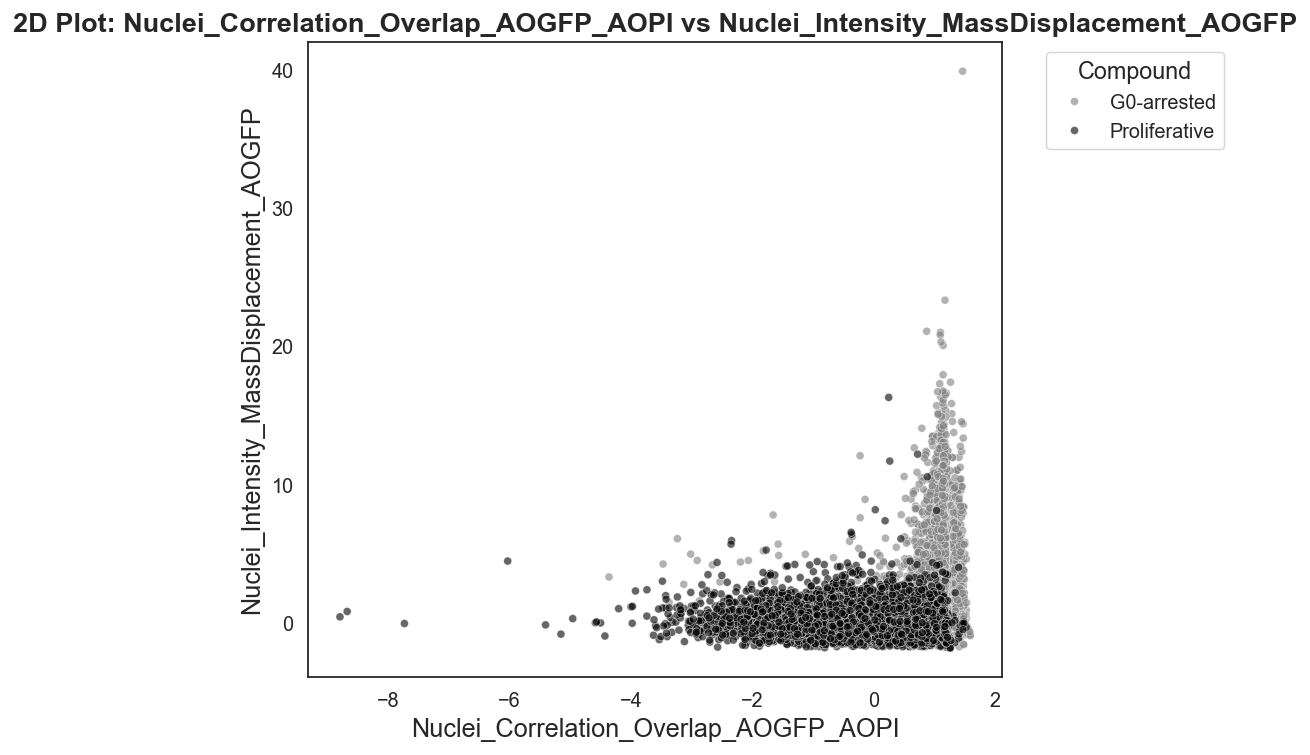

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define features to plot
x_feature = "Nuclei_Correlation_Overlap_AOGFP_AOPI"           # pode alterar
y_feature = "Nuclei_Intensity_MassDisplacement_AOGFP"      # pode alterar

# Verifica se as features existem
if x_feature in df.columns and y_feature in df.columns:
    plt.figure(figsize=(8, 6))
    
    # Define o mapa de cores manualmente
    palette = {
        df["Metadata_compound"].unique()[0]: "gray",   # primeiro grupo cinza
        df["Metadata_compound"].unique()[1]: "black"   # segundo grupo preto
    }

    sns.scatterplot(
        data=df, 
        x=x_feature, 
        y=y_feature, 
        hue="Metadata_compound", 
        alpha=0.6, 
        s=20, 
        palette=palette
    )

    plt.title(f"2D Plot: {x_feature} vs {y_feature}")
    plt.xlabel(x_feature)
    plt.ylabel(y_feature)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Compound")
    plt.tight_layout()
    plt.show()

else:
    print("Uma ou ambas as features selecionadas não existem no dataset.")


## PCA Projection of Single-Cell Features

We apply Principal Component Analysis (PCA) to reduce the high-dimensional feature space to 2 dimensions for visualization. PCA identifies directions (principal components) that capture the most variance in the data.

In this 2D scatter plot:
- Each point represents a single cell
- Colors correspond to the compound treatment class
- The axes show the first two principal components, annotated with the percentage of variance they explain

This projection helps us understand how separable the different treatments are based on the extracted morphological features.


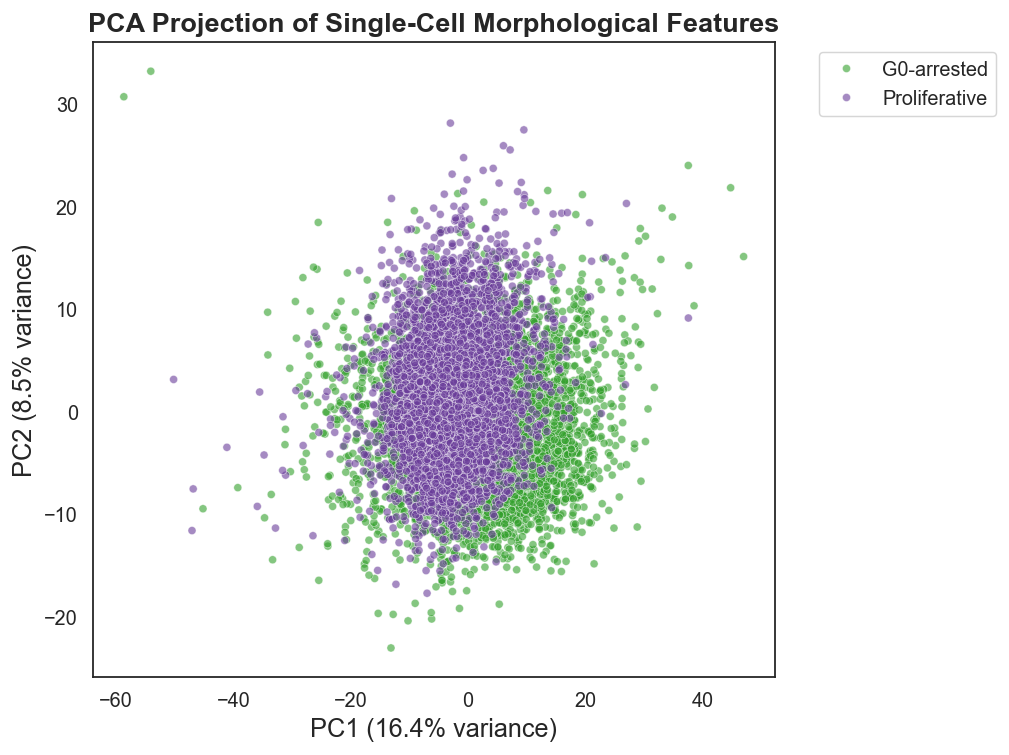

Figura salva em: /Users/thaismlacerda/Documents/PCA_projection.png


In [11]:

# Aplica PCA para reduzir para 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Cria DataFrame para plotagem
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Metadata_compound"] = y.values

pal = sns.color_palette("Paired", 12)

# Seleciona cores específicas (4ª e 9ª → índices 3 e 8, pois começa em 0)
palette = [pal[3], pal[9]]

# Plota o resultado do PCA
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Metadata_compound",
    alpha=0.6,
    s=20,
    palette=palette
)

plt.title("PCA Projection of Single-Cell Morphological Features")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="")
plt.tight_layout()

# Caminho para salvar figura na pasta do notebook
save_path = os.path.join(os.getcwd(), "PCA_projection.png")

# Salva figura em alta qualidade
plt.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Figura salva em: {save_path}")


## t-SNE Projection of Single-Cell Features

We apply t-Distributed Stochastic Neighbor Embedding (t-SNE) to project the high-dimensional feature space into 2 dimensions for visualization.

t-SNE is a nonlinear dimensionality reduction technique that preserves local structure, i.e., it places similar cells close together in the embedded space. It is especially useful when PCA or LDA fail to reveal meaningful clusters.

In this scatter plot:
- Each point represents a single cell
- Colors reflect the compound treatment class
- Axes `TSNE1` and `TSNE2` correspond to the t-SNE embedded dimensions (not actual features)

This method helps explore the intrinsic structure of the data, even when clusters are not linearly separable.


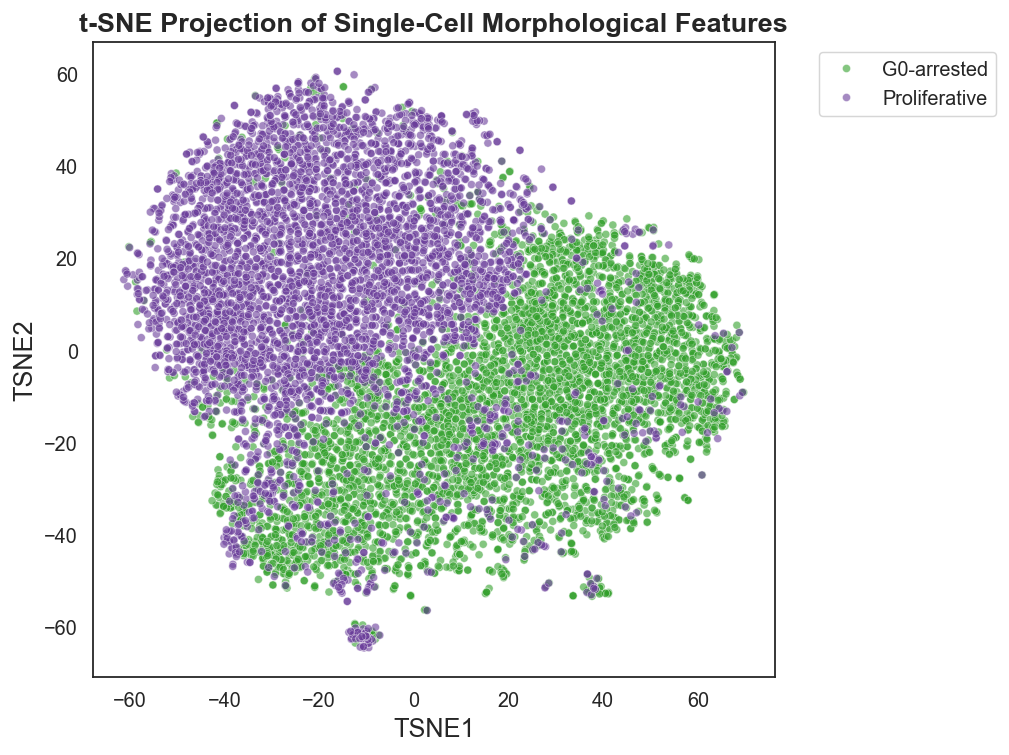

Figura salva em: /Users/thaismlacerda/Documents/TSNE_dormnondorm.png


In [12]:

# Aplica t-SNE para reduzir para 2D
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

# Cria DataFrame para plotagem
tsne_df = pd.DataFrame(X_tsne, columns=["TSNE1", "TSNE2"])
tsne_df["Metadata_compound"] = y.values

pal = sns.color_palette("Paired", 12)

# Seleciona cores específicas (4ª e 9ª → índices 3 e 8, pois começa em 0)
palette = [pal[3], pal[9]]

# Plota o resultado do t-SNE
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=tsne_df,
    x="TSNE1",
    y="TSNE2",
    hue="Metadata_compound",
    alpha=0.6,
    s=20,
    palette=palette
)

plt.title("t-SNE Projection of Single-Cell Morphological Features")
plt.xlabel("TSNE1")
plt.ylabel("TSNE2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="")
plt.tight_layout()

# Caminho para salvar figura na pasta do notebook
save_path = os.path.join(os.getcwd(), "TSNE_dormnondorm.png")

# Salva figura em alta qualidade
plt.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Figura salva em: {save_path}")


## UMAP Projection of Single-Cell Features

We use UMAP (Uniform Manifold Approximation and Projection) to reduce the feature space to 2 dimensions for visualization. UMAP is a nonlinear technique that preserves both local and global structure in the data.

In this 2D plot:
- Each point represents a single cell
- Colors indicate the compound treatment class
- The axes (`UMAP1`, `UMAP2`) are abstract dimensions capturing structure in the high-dimensional space

UMAP often creates more compact and well-separated clusters than t-SNE, while being faster and scalable to larger datasets. It is particularly useful in biological applications like single-cell analysis.


/opt/miniconda3/envs/bioimage_scripts/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


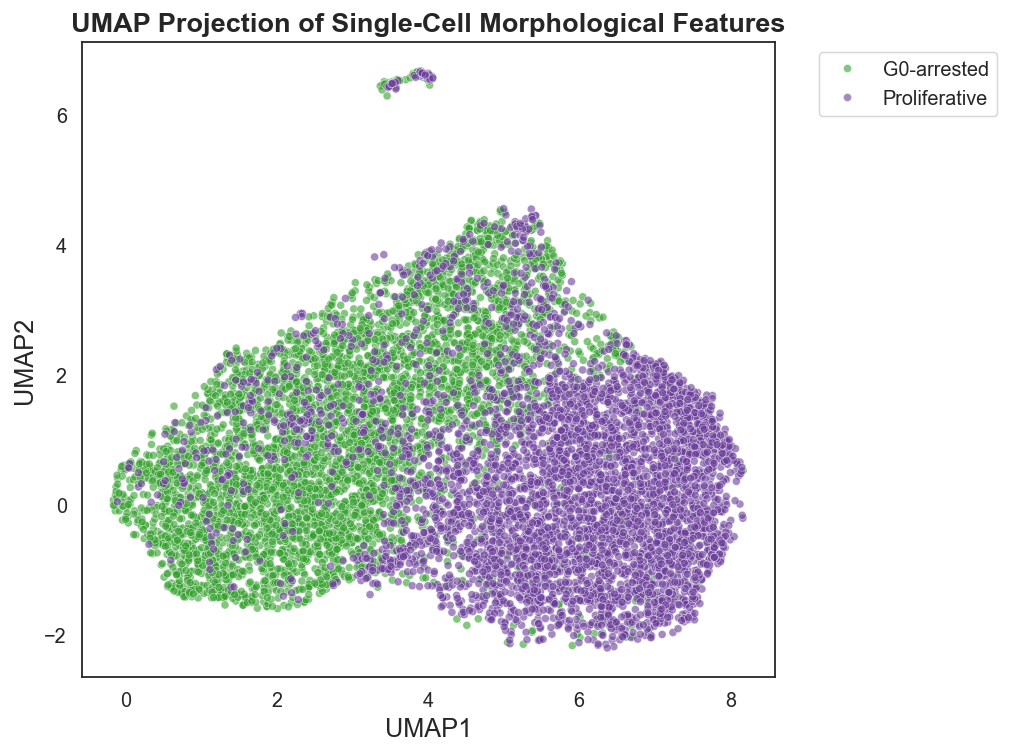

Figura salva em: /Users/thaismlacerda/Documents/UMAP_projection_highres.png


In [13]:

# Aplica UMAP para reduzir para 2D
umap_model = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
X_umap = umap_model.fit_transform(X_scaled)

# Cria DataFrame para plotagem
umap_df = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_compound"] = y.values

pal = sns.color_palette("Paired", 12)

# Seleciona cores específicas (4ª e 9ª → índices 3 e 8, pois começa em 0)
palette = [pal[3], pal[9]]

# Plota o resultado do UMAP
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="Metadata_compound",
    alpha=0.6,
    s=20,
    palette=palette
)

plt.title("UMAP Projection of Single-Cell Morphological Features")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="")
plt.tight_layout()

# Caminho para salvar figura na pasta do notebook
save_path = os.path.join(os.getcwd(), "UMAP_projection_highres.png")

# Salva figura em alta qualidade
plt.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Figura salva em: {save_path}")


## Quantitative validation at single-cell resolution

All analyses below use **individual cells as observations**. No median aggregation by well is performed. Plate and well metadata are retained only for grouping, leakage control and traceability. Dimensionality reduction, silhouette, cell-to-cell similarity, mAP, classification and SHAP therefore describe heterogeneity and discrimination at the single-cell level. Cross-validation holds out complete plates whenever plate metadata are available, preventing cells from the same plate from appearing in both training and test sets.


In [14]:
# ---------------------------------------------------------------------
# Common preparation for TRUE SINGLE-CELL quantitative validation
# ---------------------------------------------------------------------
STATE_COL = "Metadata_compound"

metadata_columns = [
    column
    for column in df.columns
    if column.startswith("Metadata_")
]

PLATE_COL = next(
    (
        column
        for column in [
            "Metadata_Plate",
            "Metadata_plate",
            "Metadata_Plate_ID",
            "Metadata_Batch",
        ]
        if column in df.columns
    ),
    None,
)

WELL_COL = next(
    (
        column
        for column in [
            "Metadata_Well",
            "Metadata_well",
            "Metadata_Well_ID",
        ]
        if column in df.columns
    ),
    None,
)

validation_features = [
    column
    for column in feature_cols
    if column in df.columns
]

single_cell_df = (
    df[
        [STATE_COL]
        + ([PLATE_COL] if PLATE_COL is not None else [])
        + ([WELL_COL] if WELL_COL is not None else [])
        + validation_features
    ]
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=[STATE_COL])
    .copy()
)

validation_features = [
    column
    for column in validation_features
    if (
        single_cell_df[column].notna().all()
        and single_cell_df[column].nunique(dropna=True) > 1
    )
]

if len(validation_features) < 2:
    raise ValueError(
        "Fewer than two complete, variable single-cell features were found."
    )

# Every row remains one individual cell.
profile_df = single_cell_df.reset_index(drop=True).copy()
PROFILE_UNIT = "single cell"

profile_scaler = StandardScaler()
profile_matrix = profile_scaler.fit_transform(
    profile_df[validation_features]
)

profile_labels = (
    profile_df[STATE_COL]
    .astype(str)
    .reset_index(drop=True)
)

label_encoder = LabelEncoder()
profile_y = label_encoder.fit_transform(profile_labels)

print("Validation unit: individual cell")
print(f"Single cells used: {len(profile_df):,}")
print(f"Morphological features used: {len(validation_features):,}")
print(f"Plate column: {PLATE_COL}")
print(f"Well column: {WELL_COL}")
display(profile_labels.value_counts().rename("Cell count"))

Validation unit: individual cell
Single cells used: 9,156
Morphological features used: 488
Plate column: Metadata_Plate
Well column: Metadata_Well


Metadata_compound
G0-arrested      4578
Proliferative    4578
Name: Cell count, dtype: int64

,Space,Silhouette score
0,Scaled morphological features,0.049151
1,PCA,0.080264


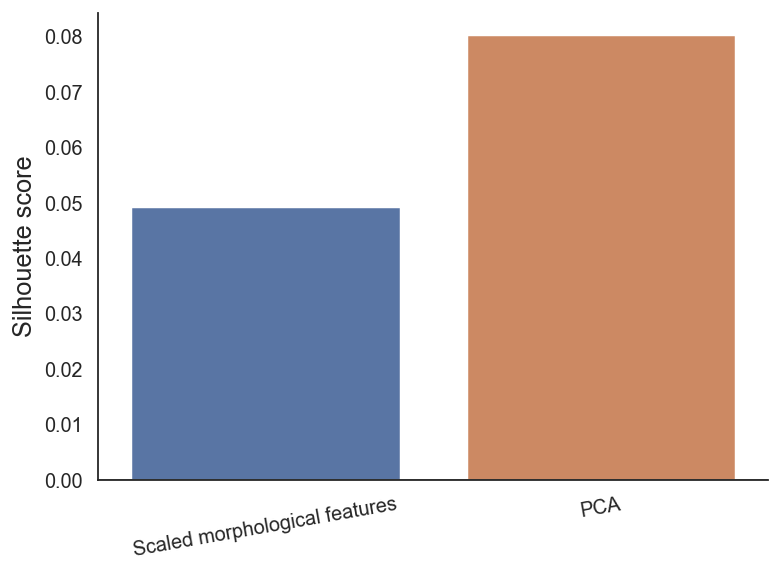

In [15]:
# ---------------------------------------------------------------------
# Silhouette score using the known biological labels
# ---------------------------------------------------------------------
# UMAP is intentionally excluded from quantitative silhouette reporting.
# Because UMAP is a nonlinear visualization optimized to preserve local
# neighborhoods, silhouette calculated in UMAP space can be inflated.
# The primary score is calculated in the scaled feature space; PCA is
# included as a secondary linear representation.

silhouette_rows = []

if len(np.unique(profile_y)) >= 2:
    silhouette_rows.append({
        "Space": "Scaled morphological features",
        "Silhouette score": silhouette_score(
            profile_matrix,
            profile_y,
        ),
    })

    n_pca_components = min(
        20,
        profile_matrix.shape[1],
        profile_matrix.shape[0] - 1,
    )

    if n_pca_components >= 2:
        profile_pca = PCA(
            n_components=n_pca_components,
            random_state=RANDOM_STATE,
        )
        profile_pca_matrix = profile_pca.fit_transform(profile_matrix)

        silhouette_rows.append({
            "Space": "PCA",
            "Silhouette score": silhouette_score(
                profile_pca_matrix,
                profile_y,
            ),
        })

silhouette_table = pd.DataFrame(silhouette_rows)
display(silhouette_table)

fig, ax = plt.subplots(figsize=(6.2, 4.6))
sns.barplot(
    data=silhouette_table,
    x="Space",
    y="Silhouette score",
    hue="Space",
    legend=False,
    ax=ax,
)
ax.axhline(0, color="#808080", linewidth=0.9)
ax.set_xlabel("")
ax.set_ylabel("Silhouette score")
ax.tick_params(axis="x", rotation=10)
sns.despine()
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "Biological_state_silhouette_scores.png"),
    dpi=400,
    bbox_inches="tight",
)
plt.show()

,Comparison,median,mean,std,count
0,G0-arrested × G0-arrested,0.032895,0.037612,0.224759,50000
1,Proliferative × Proliferative,0.052279,0.055815,0.180919,50000
2,G0-arrested × Proliferative,-0.060172,-0.050289,0.179635,50000


,Comparison,Mann–Whitney U,Raw p-value,FDR-adjusted p-value
0,G0-arrested × G0-arrested > G0-arrested × Prol...,1.550104e+09,0.0,0.0
1,Proliferative × Proliferative > G0-arrested × ...,1.658822e+09,0.0,0.0


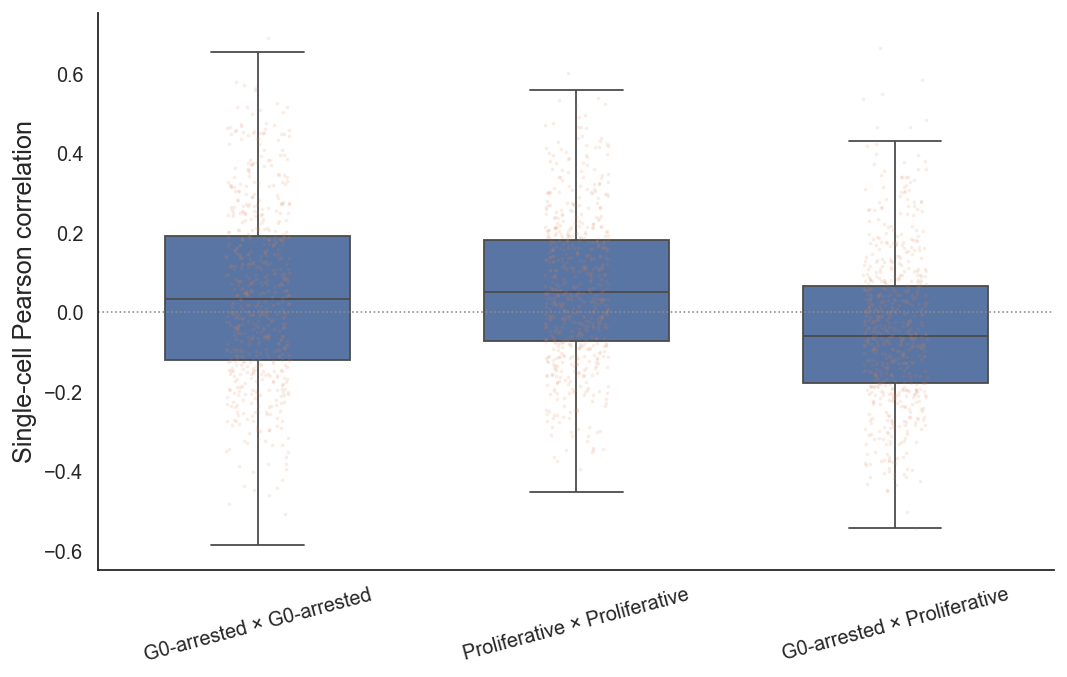

In [16]:
# ---------------------------------------------------------------------
# Intra-state and inter-state SINGLE-CELL similarity
# ---------------------------------------------------------------------
# Correlations are calculated between individual-cell feature vectors.
# Same-plate pairs are excluded when plate metadata are available.
# Pair sampling limits memory and runtime without changing the definition.

rng_similarity = np.random.default_rng(RANDOM_STATE)
comparison_targets = {
    "G0-arrested × G0-arrested": ("G0-arrested", "G0-arrested"),
    "Proliferative × Proliferative": ("Proliferative", "Proliferative"),
    "G0-arrested × Proliferative": ("G0-arrested", "Proliferative"),
}

correlation_rows = []

for comparison, (state_a, state_b) in comparison_targets.items():
    indices_a = np.flatnonzero(
        profile_labels.to_numpy() == state_a
    )
    indices_b = np.flatnonzero(
        profile_labels.to_numpy() == state_b
    )

    if len(indices_a) == 0 or len(indices_b) == 0:
        continue

    accepted = 0
    attempts = 0
    max_attempts = MAX_CORRELATION_PAIRS * 30

    while (
        accepted < MAX_CORRELATION_PAIRS
        and attempts < max_attempts
    ):
        i = int(rng_similarity.choice(indices_a))
        j = int(rng_similarity.choice(indices_b))
        attempts += 1

        if i == j:
            continue

        if (
            state_a == state_b
            and i > j
        ):
            i, j = j, i

        if (
            PLATE_COL is not None
            and profile_df.loc[i, PLATE_COL]
            == profile_df.loc[j, PLATE_COL]
        ):
            continue

        correlation = np.corrcoef(
            profile_matrix[i, :],
            profile_matrix[j, :],
        )[0, 1]

        if not np.isfinite(correlation):
            continue

        correlation_rows.append({
            "Comparison": comparison,
            "Correlation": float(correlation),
            "Cell index 1": i,
            "Cell index 2": j,
        })
        accepted += 1

correlation_table = pd.DataFrame(correlation_rows)

comparison_order = [
    comparison
    for comparison in comparison_targets
    if comparison in correlation_table["Comparison"].unique()
]

correlation_summary = (
    correlation_table
    .groupby("Comparison", observed=True)["Correlation"]
    .agg(["median", "mean", "std", "count"])
    .reindex(comparison_order)
    .reset_index()
)
display(correlation_summary)

between_label = "G0-arrested × Proliferative"
statistical_rows = []

if between_label in correlation_table["Comparison"].unique():
    between_values = correlation_table.loc[
        correlation_table["Comparison"] == between_label,
        "Correlation",
    ]

    for within_label in [
        "G0-arrested × G0-arrested",
        "Proliferative × Proliferative",
    ]:
        within_values = correlation_table.loc[
            correlation_table["Comparison"] == within_label,
            "Correlation",
        ]

        if len(within_values) > 0 and len(between_values) > 0:
            statistic, p_value = mannwhitneyu(
                within_values,
                between_values,
                alternative="greater",
            )
            statistical_rows.append({
                "Comparison": f"{within_label} > {between_label}",
                "Mann–Whitney U": statistic,
                "Raw p-value": p_value,
            })

correlation_statistics = pd.DataFrame(statistical_rows)

if not correlation_statistics.empty:
    correlation_statistics["FDR-adjusted p-value"] = multipletests(
        correlation_statistics["Raw p-value"],
        method="fdr_bh",
    )[1]

display(correlation_statistics)

fig, ax = plt.subplots(figsize=(8.4, 5.4))
sns.boxplot(
    data=correlation_table,
    x="Comparison",
    y="Correlation",
    order=comparison_order,
    showfliers=False,
    width=0.58,
    ax=ax,
)
sns.stripplot(
    data=correlation_table.groupby(
        "Comparison",
        group_keys=False,
    ).sample(
        n=min(
            600,
            correlation_table.groupby("Comparison").size().min(),
        ),
        random_state=RANDOM_STATE,
    ),
    x="Comparison",
    y="Correlation",
    order=comparison_order,
    alpha=0.14,
    size=2,
    ax=ax,
)
ax.axhline(0, color="#8A8A8A", linestyle=":", linewidth=0.9)
ax.set_xlabel("")
ax.set_ylabel("Single-cell Pearson correlation")
ax.tick_params(axis="x", rotation=15)
sns.despine()
plt.tight_layout()
plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Single_cell_intra_inter_state_correlations.png",
    ),
    dpi=400,
    bbox_inches="tight",
)
plt.show()

Single-cell overall mAP: 0.654


,State,mean,median,std,count
0,G0-arrested,0.710392,0.726425,0.120392,500
1,Proliferative,0.598285,0.603276,0.159417,500


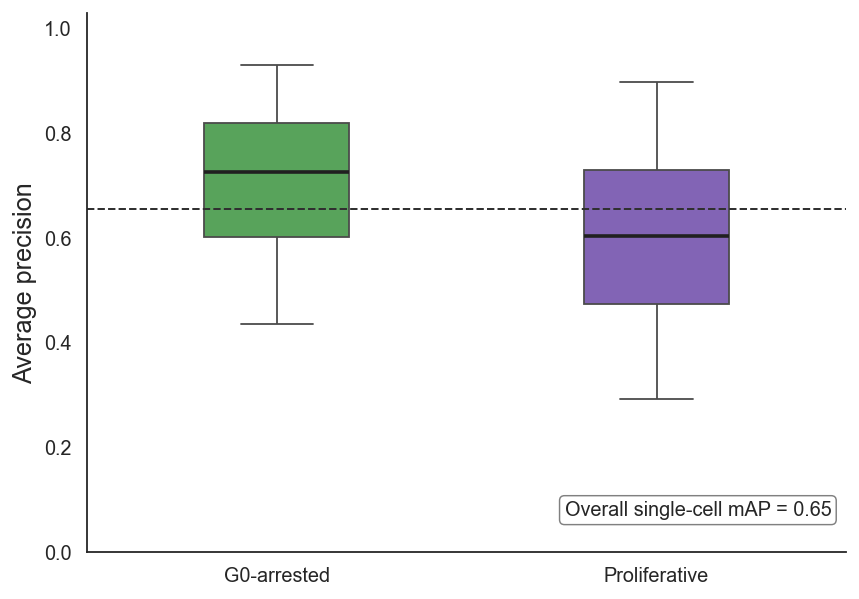

In [17]:
# ---------------------------------------------------------------------
# SINGLE-CELL Mean Average Precision (mAP)
# ---------------------------------------------------------------------
# Each query is one individual cell. Candidate cells from the same plate are
# excluded when plate metadata are available. Query sampling controls runtime.

rng_map = np.random.default_rng(RANDOM_STATE)
query_indices = []

for state in profile_labels.unique():
    state_indices = np.flatnonzero(
        profile_labels.to_numpy() == state
    )
    n_queries = min(
        MAX_MAP_QUERIES_PER_STATE,
        len(state_indices),
    )
    query_indices.extend(
        rng_map.choice(
            state_indices,
            size=n_queries,
            replace=False,
        ).tolist()
    )

map_rows = []

for query_index in query_indices:
    candidate_mask = np.ones(len(profile_df), dtype=bool)
    candidate_mask[query_index] = False

    if PLATE_COL is not None:
        candidate_mask &= (
            profile_df[PLATE_COL].to_numpy()
            != profile_df.loc[query_index, PLATE_COL]
        )

    candidate_indices = np.flatnonzero(candidate_mask)

    if len(candidate_indices) == 0:
        continue

    query_vector = profile_matrix[query_index]
    candidate_matrix = profile_matrix[candidate_indices]

    query_centered = query_vector - query_vector.mean()
    candidate_centered = (
        candidate_matrix
        - candidate_matrix.mean(axis=1, keepdims=True)
    )

    numerator = candidate_centered @ query_centered
    denominator = (
        np.linalg.norm(candidate_centered, axis=1)
        * np.linalg.norm(query_centered)
    )

    similarities = np.divide(
        numerator,
        denominator,
        out=np.full_like(numerator, np.nan, dtype=float),
        where=denominator != 0,
    )

    relevant = (
        profile_labels.iloc[candidate_indices].to_numpy()
        == profile_labels.iloc[query_index]
    ).astype(int)

    finite = np.isfinite(similarities)
    similarities = similarities[finite]
    relevant = relevant[finite]

    if relevant.sum() == 0:
        continue

    average_precision = average_precision_score(
        relevant,
        similarities,
    )

    map_rows.append({
        "State": profile_labels.iloc[query_index],
        "Average precision": float(average_precision),
        "Query cell index": int(query_index),
    })

map_table = pd.DataFrame(map_rows)

map_summary = (
    map_table
    .groupby("State", observed=True)["Average precision"]
    .agg(["mean", "median", "std", "count"])
    .reset_index()
)

overall_map = float(map_table["Average precision"].mean())

print(f"Single-cell overall mAP: {overall_map:.3f}")
display(map_summary)

fig, ax = plt.subplots(figsize=(6.8, 4.8))

state_order = [
    state
    for state in ["G0-arrested", "Proliferative"]
    if state in map_table["State"].unique()
]

sns.boxplot(
    data=map_table,
    x="State",
    y="Average precision",
    order=state_order,
    hue="State",
    palette=STATE_PALETTE,
    legend=False,
    width=0.38,
    showfliers=False,
    medianprops={
        "color": "#202020",
        "linewidth": 2.0,
    },
    ax=ax,
)

ax.axhline(
    overall_map,
    color="#303030",
    linestyle="--",
    linewidth=1.1,
)

ax.text(
    0.98,
    0.06,
    f"Overall single-cell mAP = {overall_map:.2f}",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=TICK_FONTSIZE,
    bbox={
        "boxstyle": "round,pad=0.25",
        "facecolor": "white",
        "edgecolor": "#808080",
        "linewidth": 0.8,
    },
)

ax.set_xlabel("")
ax.set_ylabel("Average precision")
ax.set_ylim(0, 1.03)
sns.despine()
ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "Single_cell_state_retrieval_mAP.png"),
    dpi=400,
    bbox_inches="tight",
)
plt.show()

,Fold,Held-out group,Training profiles,Test profiles,Training classes,Test classes,Valid binary fold
0,1,Fold 1,7324,1832,2,2,True
1,2,Fold 2,7325,1831,2,2,True
2,3,Fold 3,7325,1831,2,2,True
3,4,Fold 4,7325,1831,2,2,True
4,5,Fold 5,7325,1831,2,2,True


Stratified CV on individual cells (5 folds)
Grouping unit: single cell
Pooled balanced accuracy: 0.980
Pooled ROC AUC: 0.997
               precision    recall  f1-score   support

  G0-arrested      0.978     0.981     0.980      4578
Proliferative      0.981     0.978     0.980      4578

     accuracy                          0.980      9156
    macro avg      0.980     0.980     0.980      9156
 weighted avg      0.980     0.980     0.980      9156



,Metric,Value
0,Pooled balanced accuracy,0.979576
1,Pooled ROC AUC,0.996649
2,Mean fold balanced accuracy,0.979575
3,SD fold balanced accuracy,0.002403
4,Mean fold ROC AUC,0.996679
5,SD fold ROC AUC,0.001202


,Fold,Held-out group,Balanced accuracy,ROC AUC
0,1,Fold 1,0.983079,0.998373
1,2,Fold 2,0.977608,0.996928
2,3,Fold 3,0.979790,0.996882
3,4,Fold 4,0.977061,0.995103
4,5,Fold 5,0.980340,0.996107


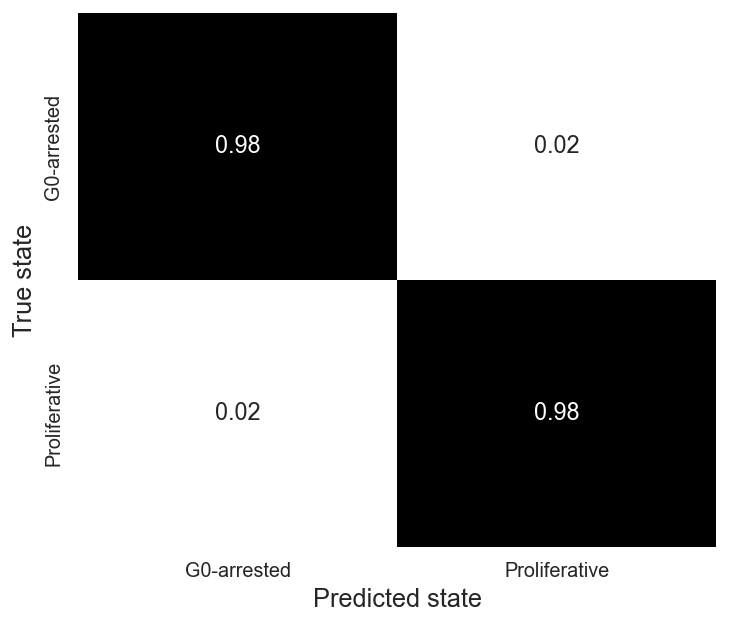

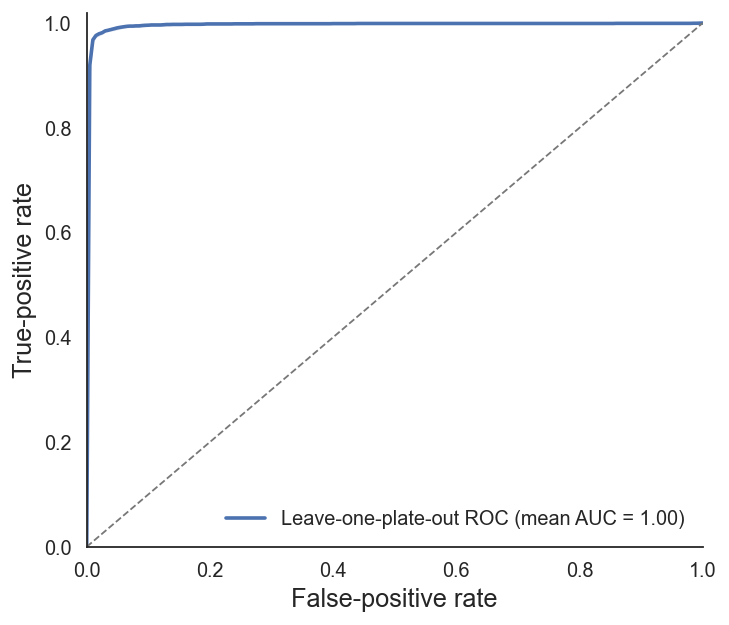

In [18]:
# ---------------------------------------------------------------------
# Cross-validated state classifier with leakage control
# ---------------------------------------------------------------------
# The classifier is evaluated on individual-cell profiles. If plate metadata
# are present, entire plates are held out. This prevents cells or wells from the
# same experimental plate from appearing in both training and test sets.

classifier = Pipeline([
    ("scaler", StandardScaler()),
    (
        "model",
        LogisticRegression(
            penalty="l2",
            class_weight="balanced",
            max_iter=5000,
            random_state=RANDOM_STATE,
        ),
    ),
])

X_classifier = single_cell_df[validation_features].reset_index(drop=True)
y_classifier = profile_y
n_profiles = len(single_cell_df)

if PLATE_COL is not None and single_cell_df[PLATE_COL].nunique() >= 3:
    groups = single_cell_df[PLATE_COL].astype(str).values
    unique_groups = np.unique(groups)
    n_splits = len(unique_groups)
    splitter = GroupKFold(n_splits=n_splits)
    split_iterator = list(
        splitter.split(X_classifier, y_classifier, groups=groups)
    )
    cv_description = (
        f"Leave-one-plate-out GroupKFold ({n_splits} folds)"
    )
    grouping_unit = "plate"
else:
    # profile_df already contains one aggregated row per well when well metadata
    # are available. Stratified CV therefore splits independent well profiles,
    # not individual cells.
    minimum_class_count = int(
        pd.Series(y_classifier).value_counts().min()
    )
    n_splits = min(5, minimum_class_count)

    if n_splits < 2:
        raise ValueError(
            "Not enough independent profiles per class for cross-validation."
        )

    splitter = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=RANDOM_STATE,
    )
    split_iterator = list(
        splitter.split(X_classifier, y_classifier)
    )
    cv_description = (
        f"Stratified CV on individual cells "
        f"({n_splits} folds)"
    )
    grouping_unit = PROFILE_UNIT

# Explicit fold audit
fold_audit_rows = []
for fold_number, (train_index, test_index) in enumerate(
    split_iterator,
    start=1,
):
    train_classes = np.unique(y_classifier[train_index])
    test_classes = np.unique(y_classifier[test_index])

    held_out_group = (
        ", ".join(sorted(set(groups[test_index])))
        if PLATE_COL is not None and "groups" in globals()
        else f"Fold {fold_number}"
    )

    fold_audit_rows.append({
        "Fold": fold_number,
        "Held-out group": held_out_group,
        "Training profiles": len(train_index),
        "Test profiles": len(test_index),
        "Training classes": len(train_classes),
        "Test classes": len(test_classes),
        "Valid binary fold": (
            len(train_classes) == 2 and len(test_classes) == 2
        ),
    })

fold_audit = pd.DataFrame(fold_audit_rows)
display(fold_audit)

valid_splits = [
    split_pair
    for split_pair, audit_row in zip(
        split_iterator,
        fold_audit_rows,
    )
    if audit_row["Valid binary fold"]
]

if len(valid_splits) < 2:
    raise ValueError(
        "Fewer than two valid folds contained both biological states. "
        "Inspect plate/state balance before interpreting classification."
    )

predicted_probability = np.full(n_profiles, np.nan)
predicted_class = np.full(n_profiles, np.nan)
fold_metric_rows = []
roc_curves = []
mean_fpr = np.linspace(0, 1, 201)

for fold_number, (train_index, test_index) in enumerate(
    valid_splits,
    start=1,
):
    fold_model = clone(classifier)
    fold_model.fit(
        X_classifier.iloc[train_index],
        y_classifier[train_index],
    )

    fold_probability = fold_model.predict_proba(
        X_classifier.iloc[test_index]
    )[:, 1]
    fold_prediction = (
        fold_probability >= 0.5
    ).astype(int)

    predicted_probability[test_index] = fold_probability
    predicted_class[test_index] = fold_prediction

    fold_balanced_accuracy = balanced_accuracy_score(
        y_classifier[test_index],
        fold_prediction,
    )
    fold_auc = roc_auc_score(
        y_classifier[test_index],
        fold_probability,
    )

    held_out_group = (
        ", ".join(sorted(set(groups[test_index])))
        if PLATE_COL is not None and "groups" in globals()
        else f"Fold {fold_number}"
    )

    fold_metric_rows.append({
        "Fold": fold_number,
        "Held-out group": held_out_group,
        "Balanced accuracy": fold_balanced_accuracy,
        "ROC AUC": fold_auc,
    })

    fold_fpr, fold_tpr, _ = roc_curve(
        y_classifier[test_index],
        fold_probability,
    )
    interpolated_tpr = np.interp(
        mean_fpr,
        fold_fpr,
        fold_tpr,
    )
    interpolated_tpr[0] = 0.0
    roc_curves.append(interpolated_tpr)

valid_prediction_mask = np.isfinite(predicted_probability)
pooled_y = y_classifier[valid_prediction_mask]
pooled_probability = predicted_probability[valid_prediction_mask]
pooled_prediction = predicted_class[valid_prediction_mask].astype(int)

prediction_table = profile_df.loc[
    valid_prediction_mask,
    [
        STATE_COL,
        *(
            [PLATE_COL]
            if PLATE_COL is not None
            else []
        ),
        *(
            [WELL_COL]
            if WELL_COL is not None
            else []
        ),
    ],
].copy()

prediction_table["Observed class"] = label_encoder.inverse_transform(
    pooled_y
)
prediction_table["Predicted class"] = label_encoder.inverse_transform(
    pooled_prediction
)
prediction_table["Predicted probability"] = pooled_probability

balanced_accuracy = balanced_accuracy_score(
    pooled_y,
    pooled_prediction,
)
roc_auc = roc_auc_score(
    pooled_y,
    pooled_probability,
)

fold_metrics = pd.DataFrame(fold_metric_rows)

classifier_metrics = pd.DataFrame({
    "Metric": [
        "Pooled balanced accuracy",
        "Pooled ROC AUC",
        "Mean fold balanced accuracy",
        "SD fold balanced accuracy",
        "Mean fold ROC AUC",
        "SD fold ROC AUC",
    ],
    "Value": [
        balanced_accuracy,
        roc_auc,
        fold_metrics["Balanced accuracy"].mean(),
        fold_metrics["Balanced accuracy"].std(ddof=1),
        fold_metrics["ROC AUC"].mean(),
        fold_metrics["ROC AUC"].std(ddof=1),
    ],
})

print(cv_description)
print(f"Grouping unit: {grouping_unit}")
print(f"Pooled balanced accuracy: {balanced_accuracy:.3f}")
print(f"Pooled ROC AUC: {roc_auc:.3f}")
print(
    classification_report(
        pooled_y,
        pooled_prediction,
        target_names=label_encoder.classes_,
        digits=3,
    )
)
display(classifier_metrics)
display(fold_metrics)


# Supplementary normalized confusion matrix
cm = confusion_matrix(
    pooled_y,
    pooled_prediction,
    normalize="true",
)

fig, ax = plt.subplots(figsize=(5.8, 5.0))
sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Greys",
    cbar=False,
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    ax=ax,
)
ax.set_xlabel("Predicted state")
ax.set_ylabel("True state")
ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "State_classifier_confusion_matrix.png"),
    dpi=400,
    bbox_inches="tight",
)
plt.show()

# Mean cross-validated ROC with fold-to-fold variability
roc_matrix = np.vstack(roc_curves)
mean_tpr = roc_matrix.mean(axis=0)
std_tpr = roc_matrix.std(axis=0, ddof=1)
mean_tpr[-1] = 1.0

lower_tpr = np.maximum(mean_tpr - std_tpr, 0)
upper_tpr = np.minimum(mean_tpr + std_tpr, 1)

fig, ax = plt.subplots(figsize=(5.8, 5.0))
ax.plot(
    mean_fpr,
    mean_tpr,
    linewidth=2.0,
    label=(
        "Leave-one-plate-out ROC "
        f"(mean AUC = {fold_metrics['ROC AUC'].mean():.2f})"
    ),
)
ax.fill_between(
    mean_fpr,
    lower_tpr,
    upper_tpr,
    alpha=0.18,
)
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.0,
    color="#777777",
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("False-positive rate")
ax.set_ylabel("True-positive rate")
ax.legend(frameon=False, loc="lower right")
sns.despine()
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "State_classifier_ROC_curve.png"),
    dpi=400,
    bbox_inches="tight",
)
plt.show()

### Morphology-based phenotype probability with calibration audit

The primary continuous quantity is **P(Proliferative morphology)**, calculated from leave-one-plate-out predictions using the original morphological features. The calibration curve and Brier score indicate whether this output can be interpreted as a calibrated probability.

The categorical UMAP and phenotype-assignment matrix use the same thresholds: **G0-like = P(Proliferative) ≤ 0.30**, **Intermediate = 0.30–0.70**, and **Proliferative-like = P(Proliferative) ≥ 0.70**. G0 is green, proliferative morphology purple, and intermediate cells amber.

These probabilities describe morphology-based resemblance to the proliferative reference state; they do not by themselves prove functional cell-cycle state.


,Biological comparison,Cells (%),CI low (%),CI high (%),Definition,Bootstrap unit
0,G0-arrested cells with strongly Proliferative-...,1.310616,1.223691,2.032520,P(Proliferative) >= 0.70,plate
1,Proliferative cells with strongly G0-like morp...,1.681957,1.638566,2.179837,P(Proliferative) <= 0.30,plate


Morphology-based identity,G0-like,Intermediate,Proliferative-like
Observed class,,,
G0-arrested,97.34,1.35,1.31
Proliferative,1.68,1.16,97.16


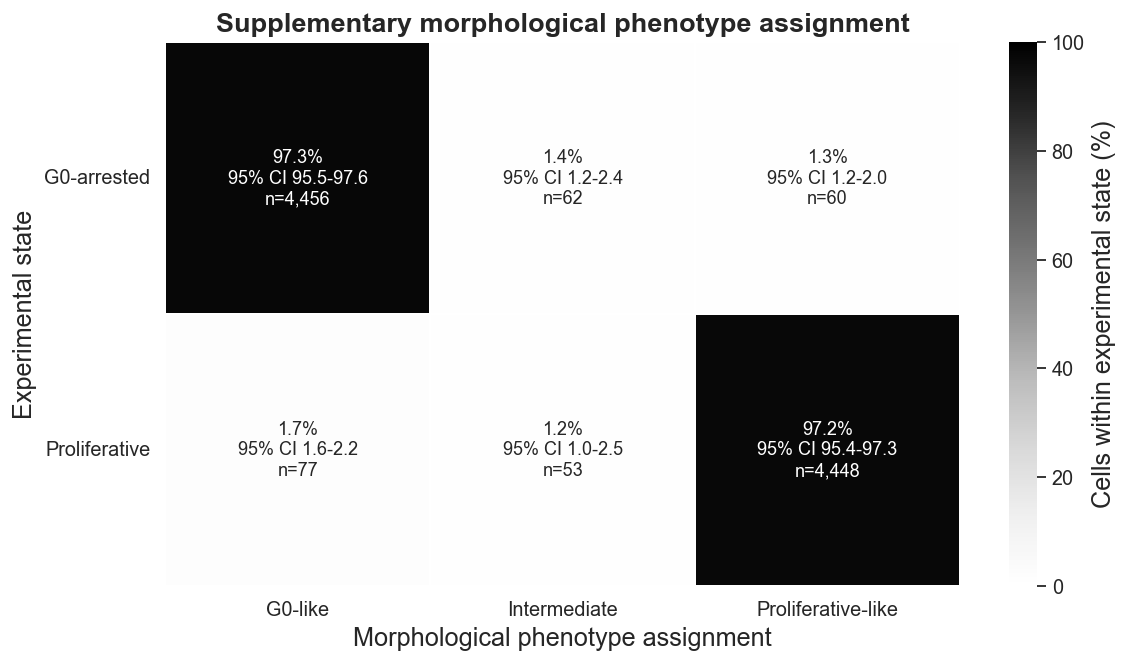

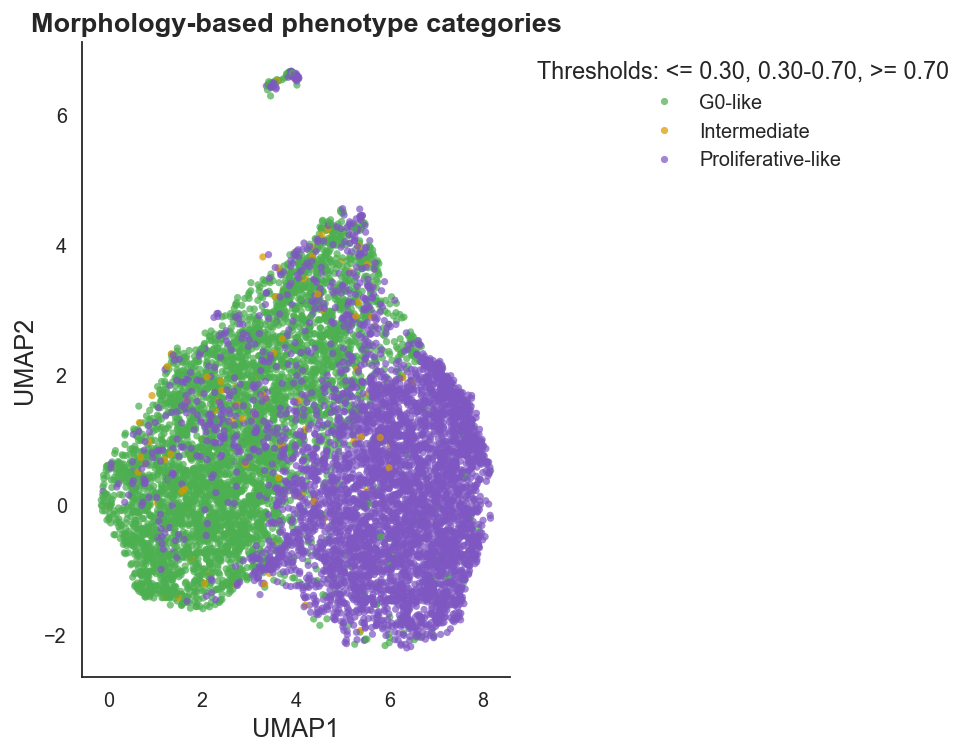

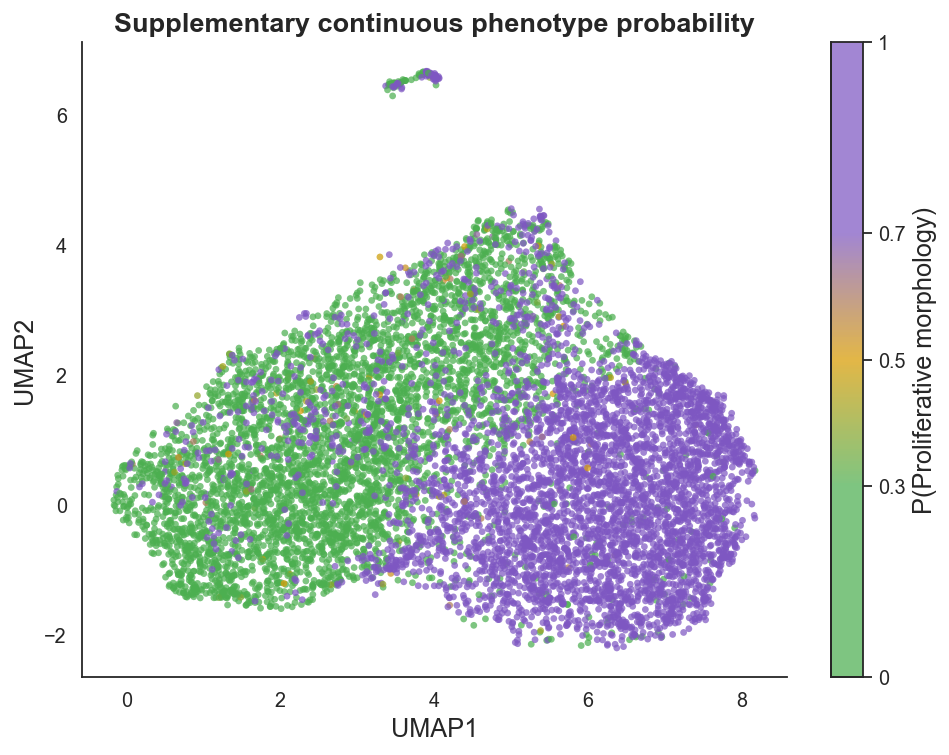

Out-of-fold Brier score: 0.0163


,Metric,Value
0,Brier score,0.01628
1,Number of calibration bins,10
2,Calibration strategy,Quantile


,Mean predicted probability,Observed proliferative fraction
0,2.816900e-08,0.004367
1,9.060725e-07,0.000000
2,1.340561e-05,0.001093
3,2.384509e-04,0.004367
4,5.292853e-02,0.091803
5,9.385954e-01,0.905022
6,9.997500e-01,0.995628
7,9.999833e-01,1.000000
8,9.999987e-01,0.998907
9,1.000000e+00,0.998908


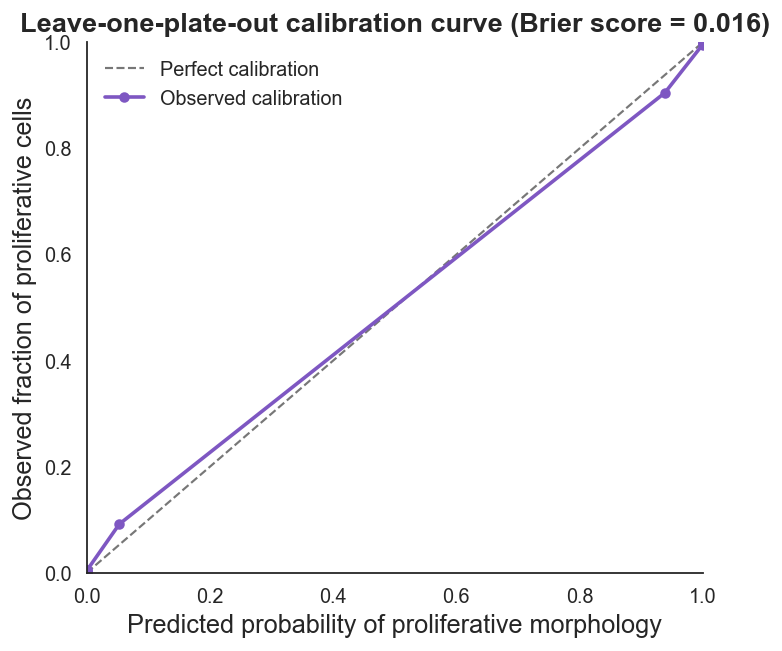

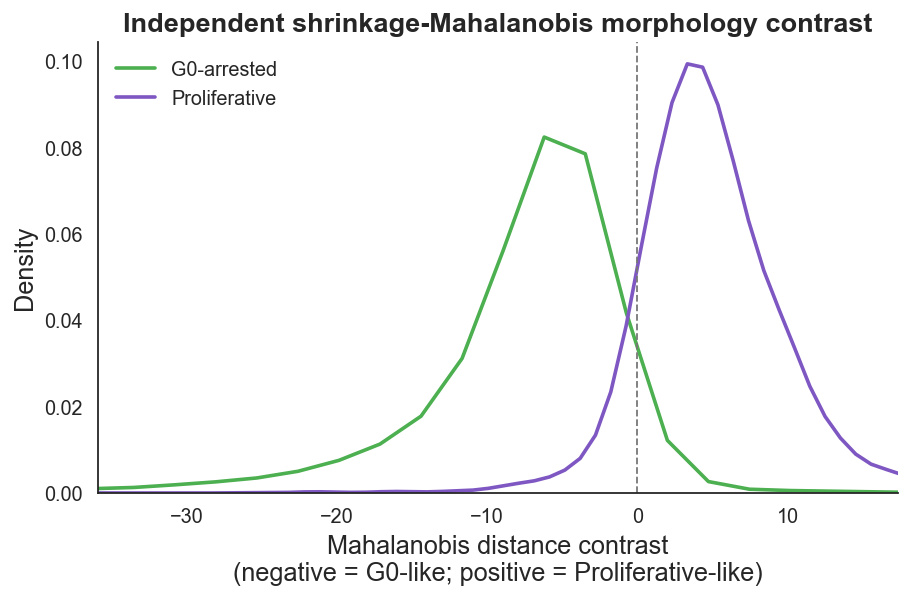

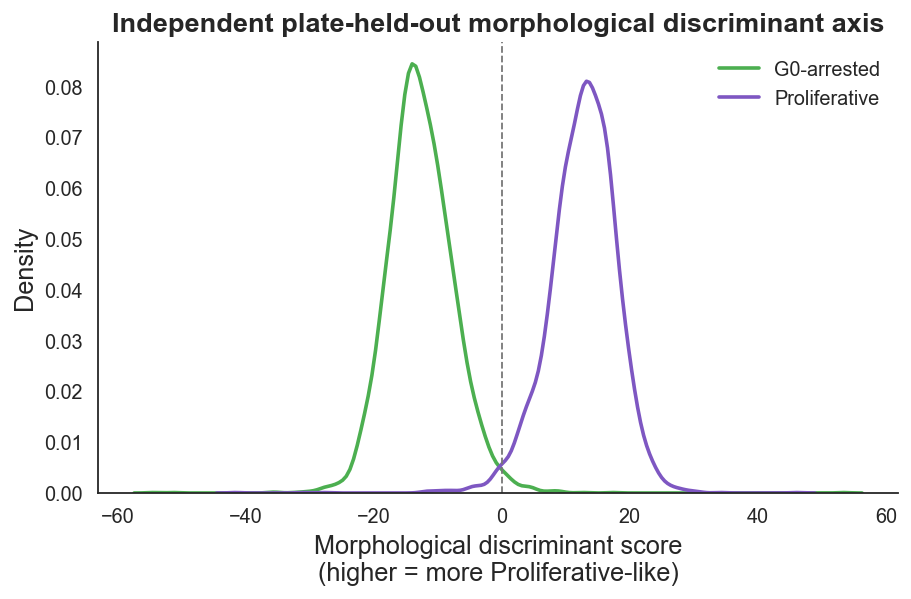

,Method,G0 to Proliferative-like (%),Proliferative to G0-like (%),Overall agreement with observed state (%)
0,Logistic probability,1.878550,2.206204,97.957623
1,Shrinkage Mahalanobis,2.228047,10.834426,93.468764
2,Regularized LDA,1.332460,1.725644,98.470948


,Comparison,Pearson r,Pearson p-value,Spearman rho,Spearman p-value
0,Probability vs Mahalanobis contrast,0.534865,0.0,0.849080,0.0
1,Probability vs morphological discriminant score,0.937918,0.0,0.968023,0.0


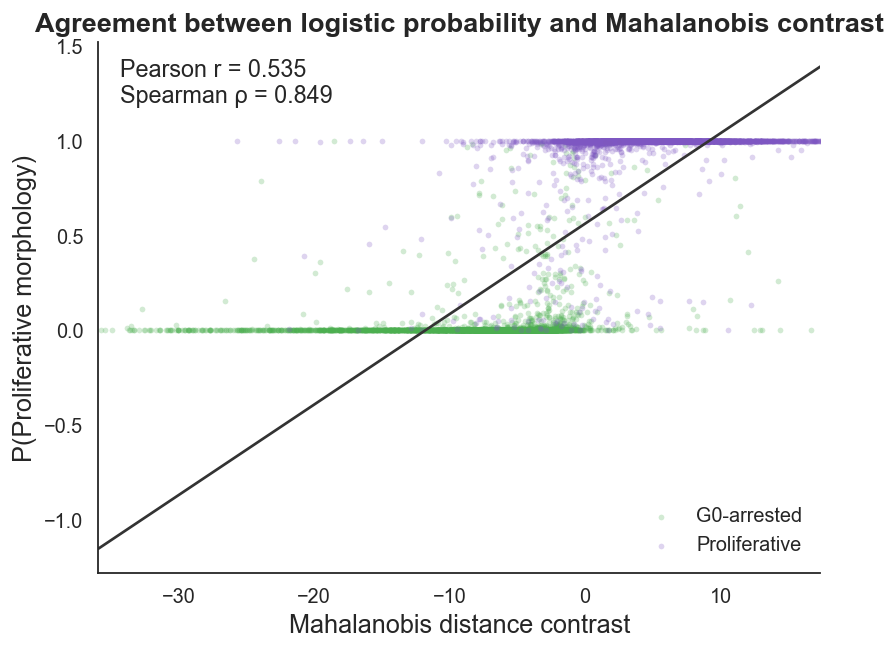

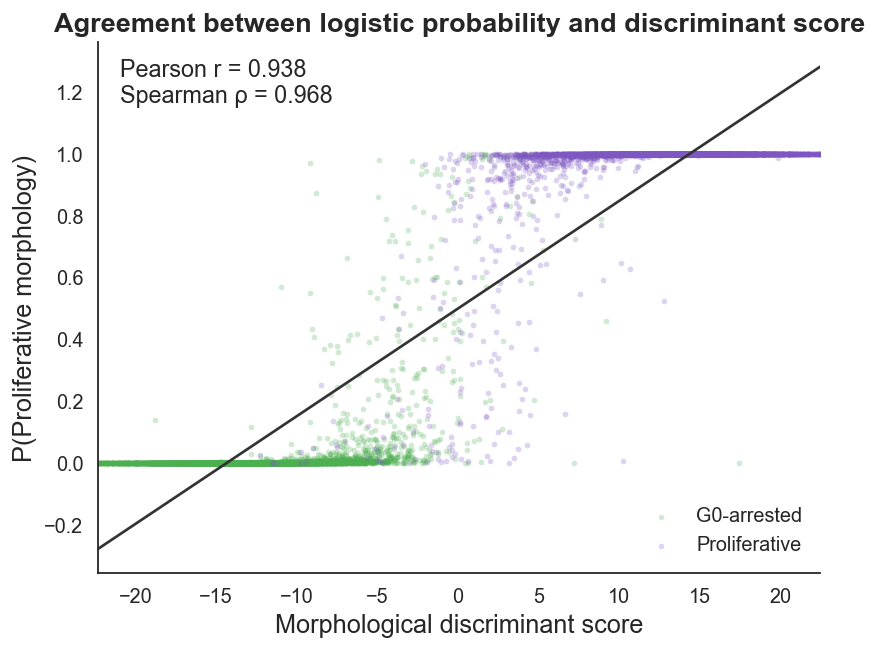

,Method,G0 to Proliferative-like (%),Proliferative to G0-like (%),Overall agreement with observed state (%),ROC AUC
0,Logistic probability,1.878550,2.206204,97.957623,0.996649
1,Shrinkage Mahalanobis,2.228047,10.834426,93.468764,0.973517
2,Regularized LDA,1.332460,1.725644,98.470948,0.997261


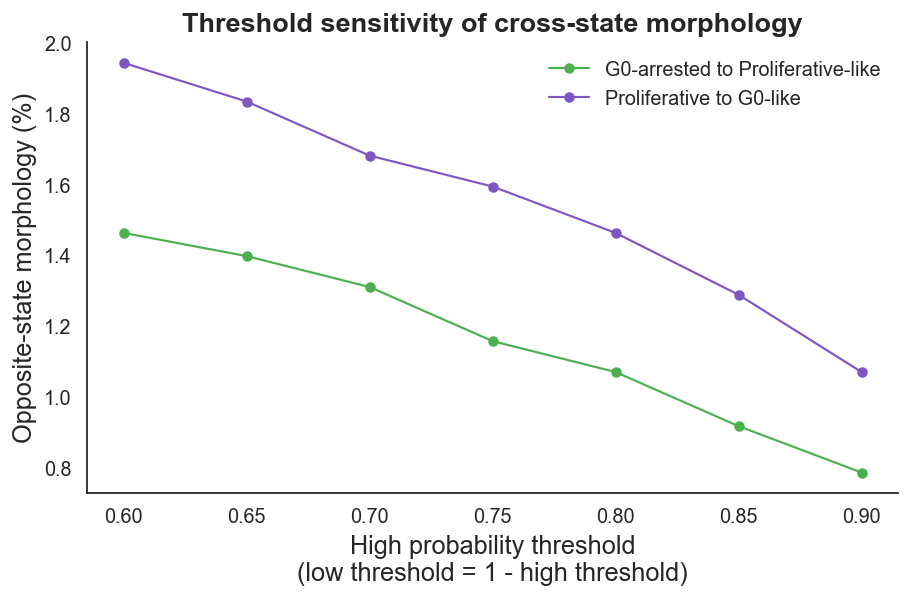

In [19]:
# ---------------------------------------------------------------------
# Publication-focused morphology-based phenotypic identity analysis
# ---------------------------------------------------------------------
# Primary readouts are continuous and calculated from the original
# morphological features with plate-held-out predictions.
#
# Colour convention used throughout:
#   G0-arrested / G0-like       = green
#   Proliferative / Prolif-like = purple
#
# Discrete threshold-based categories use moderately stringent cut-offs
# and are matched exactly between the matrix and categorical UMAP. UMAP is used only for visualisation.
# ---------------------------------------------------------------------
PHENOTYPIC_LOW_THRESHOLD = 0.30
PHENOTYPIC_HIGH_THRESHOLD = 0.70
N_BOOTSTRAP = 2000
BOOTSTRAP_RANDOM_STATE = 2026
G0_COLOR = STATE_PALETTE.get("G0-arrested", "#4CAF50")
PROLIF_COLOR = STATE_PALETTE.get("Proliferative", "#7E57C2")
INTERMEDIATE_COLOR = "#D89B00"  # saturated amber for visibility
if not (
    0 <= PHENOTYPIC_LOW_THRESHOLD
    < PHENOTYPIC_HIGH_THRESHOLD
    <= 1
):
    raise ValueError(
        "Phenotypic probability thresholds must satisfy "
        "0 <= low < high <= 1."
    )
class_names = list(label_encoder.classes_)
g0_state = next(
    (state for state in class_names if "G0" in state.upper()),
    class_names[0],
)
proliferative_state = next(
    (state for state in class_names if "PROLIF" in state.upper()),
    class_names[-1],
)
g0_encoded = int(label_encoder.transform([g0_state])[0])
proliferative_encoded = int(
    label_encoder.transform([proliferative_state])[0]
)
positive_model_class = label_encoder.inverse_transform([1])[0]
if positive_model_class == proliferative_state:
    proliferative_probability = pooled_probability.copy()
elif positive_model_class == g0_state:
    proliferative_probability = 1.0 - pooled_probability
else:
    raise ValueError(
        "Could not determine which encoded class represents "
        "the proliferative state."
    )
phenotypic_identity = np.select(
    [
        proliferative_probability <= PHENOTYPIC_LOW_THRESHOLD,
        proliferative_probability >= PHENOTYPIC_HIGH_THRESHOLD,
    ],
    ["G0-like", "Proliferative-like"],
    default="Intermediate",
)
identity_order = [
    "G0-like",
    "Intermediate",
    "Proliferative-like",
]
phenotypic_identity_table = prediction_table.copy()
phenotypic_identity_table[
    "P(Proliferative morphology)"
] = proliferative_probability
phenotypic_identity_table[
    "Morphology-based identity"
] = phenotypic_identity
# ---------------------------------------------------------------------
# Supplementary threshold-based identity matrix
# ---------------------------------------------------------------------
phenotypic_identity_counts = pd.crosstab(
    phenotypic_identity_table["Observed class"],
    phenotypic_identity_table["Morphology-based identity"],
).reindex(
    index=[g0_state, proliferative_state],
    columns=identity_order,
    fill_value=0,
)
phenotypic_identity_percent = (
    phenotypic_identity_counts
    .div(
        phenotypic_identity_counts.sum(axis=1),
        axis=0,
    )
    * 100
)
# Cluster-aware bootstrap: resample plates when possible, otherwise wells.
if (
    PLATE_COL is not None
    and PLATE_COL in phenotypic_identity_table.columns
    and phenotypic_identity_table[PLATE_COL].nunique() >= 2
):
    bootstrap_unit_col = PLATE_COL
    bootstrap_unit_label = "plate"
elif (
    WELL_COL is not None
    and WELL_COL in phenotypic_identity_table.columns
    and phenotypic_identity_table[WELL_COL].nunique() >= 2
):
    bootstrap_unit_col = WELL_COL
    bootstrap_unit_label = "well"
else:
    bootstrap_unit_col = None
    bootstrap_unit_label = "cell"
rng = np.random.default_rng(BOOTSTRAP_RANDOM_STATE)
bootstrap_records = []
for observed_state in [g0_state, proliferative_state]:
    state_table = phenotypic_identity_table.loc[
        phenotypic_identity_table["Observed class"].astype(str)
        == observed_state
    ].copy()
    for bootstrap_index in range(N_BOOTSTRAP):
        if bootstrap_unit_col is not None:
            units = state_table[
                bootstrap_unit_col
            ].astype(str).unique()
            sampled_units = rng.choice(
                units,
                size=len(units),
                replace=True,
            )
            sampled_table = pd.concat(
                [
                    state_table.loc[
                        state_table[bootstrap_unit_col].astype(str)
                        == unit
                    ]
                    for unit in sampled_units
                ],
                ignore_index=True,
            )
        else:
            sampled_table = state_table.sample(
                n=len(state_table),
                replace=True,
                random_state=int(
                    rng.integers(0, 2**31 - 1)
                ),
            )
        category_percent = (
            sampled_table["Morphology-based identity"]
            .value_counts(normalize=True)
            .reindex(identity_order, fill_value=0)
            * 100
        )
        for identity in identity_order:
            bootstrap_records.append({
                "Bootstrap": bootstrap_index,
                "Observed state": observed_state,
                "Morphology-based identity": identity,
                "Cells (%)": float(
                    category_percent.loc[identity]
                ),
            })
phenotypic_identity_bootstrap = pd.DataFrame(
    bootstrap_records
)
phenotypic_identity_ci = (
    phenotypic_identity_bootstrap
    .groupby(
        ["Observed state", "Morphology-based identity"],
        observed=True,
    )["Cells (%)"]
    .agg(
        CI_low=lambda values: np.percentile(values, 2.5),
        CI_high=lambda values: np.percentile(values, 97.5),
    )
    .reset_index()
)
phenotypic_identity_ci["Bootstrap unit"] = (
    bootstrap_unit_label
)
identity_ci_lookup = phenotypic_identity_ci.set_index(
    ["Observed state", "Morphology-based identity"]
)
g0_proliferative_like_percent = float(
    phenotypic_identity_percent.loc[
        g0_state,
        "Proliferative-like",
    ]
)
proliferative_g0_like_percent = float(
    phenotypic_identity_percent.loc[
        proliferative_state,
        "G0-like",
    ]
)
phenotypic_crossover_summary = pd.DataFrame({
    "Biological comparison": [
        f"{g0_state} cells with strongly Proliferative-like morphology",
        f"{proliferative_state} cells with strongly G0-like morphology",
    ],
    "Cells (%)": [
        g0_proliferative_like_percent,
        proliferative_g0_like_percent,
    ],
    "CI low (%)": [
        identity_ci_lookup.loc[
            (g0_state, "Proliferative-like"),
            "CI_low",
        ],
        identity_ci_lookup.loc[
            (proliferative_state, "G0-like"),
            "CI_low",
        ],
    ],
    "CI high (%)": [
        identity_ci_lookup.loc[
            (g0_state, "Proliferative-like"),
            "CI_high",
        ],
        identity_ci_lookup.loc[
            (proliferative_state, "G0-like"),
            "CI_high",
        ],
    ],
    "Definition": [
        f"P(Proliferative) >= {PHENOTYPIC_HIGH_THRESHOLD:.2f}",
        f"P(Proliferative) <= {PHENOTYPIC_LOW_THRESHOLD:.2f}",
    ],
    "Bootstrap unit": [
        bootstrap_unit_label,
        bootstrap_unit_label,
    ],
})
display(phenotypic_crossover_summary)
display(phenotypic_identity_percent.round(2))
identity_annotations = np.empty_like(
    phenotypic_identity_percent.to_numpy(),
    dtype=object,
)
for row_index, observed_state in enumerate(
    phenotypic_identity_percent.index
):
    for column_index, identity in enumerate(
        phenotypic_identity_percent.columns
    ):
        value = float(
            phenotypic_identity_percent.loc[
                observed_state,
                identity,
            ]
        )
        count = int(
            phenotypic_identity_counts.loc[
                observed_state,
                identity,
            ]
        )
        ci_low = float(
            identity_ci_lookup.loc[
                (observed_state, identity),
                "CI_low",
            ]
        )
        ci_high = float(
            identity_ci_lookup.loc[
                (observed_state, identity),
                "CI_high",
            ]
        )
        identity_annotations[
            row_index,
            column_index,
        ] = (
            f"{value:.1f}%\n"
            f"95% CI {ci_low:.1f}-{ci_high:.1f}\n"
            f"n={count:,}"
        )
fig, ax = plt.subplots(figsize=(9.2, 5.3))
sns.heatmap(
    phenotypic_identity_percent,
    annot=identity_annotations,
    fmt="",
    cmap="Greys",
    vmin=0,
    vmax=100,
    linewidths=1.0,
    linecolor="white",
    annot_kws={"fontsize": HEATMAP_ANNOT_FONTSIZE},
    cbar_kws={
        "label": "Cells within experimental state (%)",
    },
    ax=ax,
)
ax.set_xlabel("Morphological phenotype assignment")
ax.set_ylabel("Experimental state")
ax.set_title(
    "Supplementary morphological phenotype assignment"
)
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Supplementary_single_cell_morphological_phenotype_assignment_matrix.png",
    ),
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
# ---------------------------------------------------------------------
# Primary visualisation: categorical UMAP using the SAME thresholds
# as the phenotype-assignment matrix
# ---------------------------------------------------------------------
if "X_umap" in globals():
    if len(X_umap) != len(single_cell_df):
        raise ValueError(
            "X_umap and single_cell_df have different lengths. "
            "Re-run the notebook sequentially."
        )
    phenotypic_umap_table = pd.DataFrame({
        "UMAP1": X_umap[valid_prediction_mask, 0],
        "UMAP2": X_umap[valid_prediction_mask, 1],
        "Observed state": phenotypic_identity_table[
            "Observed class"
        ].astype(str).to_numpy(),
        "P(Proliferative morphology)": (
            proliferative_probability
        ),
        "Morphology-based identity": phenotypic_identity,
    })
    identity_palette = {
        "G0-like": G0_COLOR,
        "Intermediate": INTERMEDIATE_COLOR,
        "Proliferative-like": PROLIF_COLOR,
    }
    fig, ax = plt.subplots(figsize=(7.7, 6.0))
    sns.scatterplot(
        data=phenotypic_umap_table,
        x="UMAP1",
        y="UMAP2",
        hue="Morphology-based identity",
        hue_order=identity_order,
        palette=identity_palette,
        s=16,
        alpha=0.72,
        linewidth=0,
        ax=ax,
    )
    ax.set_xlabel("UMAP1", fontsize=AXIS_LABEL_FONTSIZE)
    ax.set_ylabel("UMAP2", fontsize=AXIS_LABEL_FONTSIZE)
    ax.set_title(
        "Morphology-based phenotype categories",
        fontsize=TITLE_FONTSIZE,
    )
    ax.legend(
        title=(
            f"Thresholds: <= {PHENOTYPIC_LOW_THRESHOLD:.2f}, "
            f"{PHENOTYPIC_LOW_THRESHOLD:.2f}-{PHENOTYPIC_HIGH_THRESHOLD:.2f}, "
            f">= {PHENOTYPIC_HIGH_THRESHOLD:.2f}"
        ),
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False,
        fontsize=LEGEND_FONTSIZE,
        title_fontsize=LEGEND_TITLE_FONTSIZE,
    )
    ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)
    sns.despine()
    plt.tight_layout()
    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "Main_single_cell_UMAP_categorical_phenotypic_identity.png",
        ),
        dpi=400,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()
    # Supplementary continuous probability view
    from matplotlib.colors import LinearSegmentedColormap
    g0_to_prolif_cmap = LinearSegmentedColormap.from_list(
        "G0_to_Proliferative",
        [
            (0.00, G0_COLOR),
            (0.30, G0_COLOR),
            (0.50, INTERMEDIATE_COLOR),
            (0.70, PROLIF_COLOR),
            (1.00, PROLIF_COLOR),
        ],
    )
    fig, ax = plt.subplots(figsize=(7.7, 6.0))
    scatter = ax.scatter(
        phenotypic_umap_table["UMAP1"],
        phenotypic_umap_table["UMAP2"],
        c=phenotypic_umap_table[
            "P(Proliferative morphology)"
        ],
        cmap=g0_to_prolif_cmap,
        vmin=0,
        vmax=1,
        s=14,
        alpha=0.72,
        linewidths=0,
    )
    cbar = fig.colorbar(scatter, ax=ax)
    cbar.set_label(
        "P(Proliferative morphology)"
    )
    cbar.set_ticks([0, 0.3, 0.5, 0.7, 1])
    cbar.set_ticklabels(["0", "0.3", "0.5", "0.7", "1"])
    cbar.ax.tick_params(labelsize=COLORBAR_TICK_FONTSIZE)
    ax.set_xlabel("UMAP1", fontsize=AXIS_LABEL_FONTSIZE)
    ax.set_ylabel("UMAP2", fontsize=AXIS_LABEL_FONTSIZE)
    ax.set_title(
        "Supplementary continuous phenotype probability"
    )
    sns.despine()
    plt.tight_layout()
    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "Supplementary_single_cell_UMAP_continuous_phenotypic_probability.png",
        ),
        dpi=400,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()
# ---------------------------------------------------------------------
# Probability calibration audit
# ---------------------------------------------------------------------
# This determines whether leave-one-plate-out logistic outputs can be
# interpreted as calibrated probabilities of proliferative morphology.
calibration_fraction_positive, calibration_mean_predicted = (
    calibration_curve(
        pooled_y,
        pooled_probability,
        n_bins=10,
        strategy="quantile",
    )
)
classifier_brier_score = brier_score_loss(
    pooled_y,
    pooled_probability,
)
calibration_table = pd.DataFrame({
    "Mean predicted probability": calibration_mean_predicted,
    "Observed proliferative fraction": calibration_fraction_positive,
})
calibration_summary = pd.DataFrame({
    "Metric": [
        "Brier score",
        "Number of calibration bins",
        "Calibration strategy",
    ],
    "Value": [
        classifier_brier_score,
        len(calibration_table),
        "Quantile",
    ],
})
print(
    f"Out-of-fold Brier score: "
    f"{classifier_brier_score:.4f}"
)
display(calibration_summary)
display(calibration_table)
fig, ax = plt.subplots(figsize=(5.8, 5.2))
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.2,
    color="#777777",
    label="Perfect calibration",
)
ax.plot(
    calibration_mean_predicted,
    calibration_fraction_positive,
    marker="o",
    linewidth=2.0,
    color=PROLIF_COLOR,
    label="Observed calibration",
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Predicted probability of proliferative morphology")
ax.set_ylabel("Observed fraction of proliferative cells")
ax.set_title(
    f"Leave-one-plate-out calibration curve "
    f"(Brier score = {classifier_brier_score:.3f})"
)
ax.legend(
    title="",
    frameon=False,
    loc="upper left",
)
sns.despine()
plt.tight_layout()
plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Supplementary_classifier_calibration_curve.png",
    ),
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
# ---------------------------------------------------------------------
# Independent plate-held-out morphology scores
# ---------------------------------------------------------------------
mahalanobis_delta = np.full(n_profiles, np.nan)
lda_decision_score = np.full(n_profiles, np.nan)
for train_index, test_index in valid_splits:
    fold_scaler = StandardScaler()
    X_train_scaled = fold_scaler.fit_transform(
        X_classifier.iloc[train_index]
    )
    X_test_scaled = fold_scaler.transform(
        X_classifier.iloc[test_index]
    )
    y_train_fold = y_classifier[train_index]
    g0_train = X_train_scaled[
        y_train_fold == g0_encoded
    ]
    proliferative_train = X_train_scaled[
        y_train_fold == proliferative_encoded
    ]
    if len(g0_train) < 2 or len(proliferative_train) < 2:
        continue
    g0_covariance = LedoitWolf().fit(g0_train)
    proliferative_covariance = LedoitWolf().fit(
        proliferative_train
    )
    distance_to_g0 = np.sqrt(
        g0_covariance.mahalanobis(X_test_scaled)
    )
    distance_to_proliferative = np.sqrt(
        proliferative_covariance.mahalanobis(
            X_test_scaled
        )
    )
    # Positive values mean closer to the proliferative reference.
    # Negative values mean closer to the G0 reference.
    fold_delta = (
        distance_to_g0 - distance_to_proliferative
    )
    mahalanobis_delta[test_index] = fold_delta
    fold_lda = LDA(
        solver="lsqr",
        shrinkage="auto",
    )
    fold_lda.fit(
        X_train_scaled,
        y_train_fold,
    )
    fold_lda_score = fold_lda.decision_function(
        X_test_scaled
    )
    if int(fold_lda.classes_[1]) != proliferative_encoded:
        fold_lda_score = -fold_lda_score
    lda_decision_score[test_index] = fold_lda_score
independent_valid_mask = (
    valid_prediction_mask
    & np.isfinite(mahalanobis_delta)
    & np.isfinite(lda_decision_score)
)
independent_score_table = profile_df.loc[
    independent_valid_mask,
    [
        STATE_COL,
        *([PLATE_COL] if PLATE_COL is not None else []),
        *([WELL_COL] if WELL_COL is not None else []),
    ],
].copy()
independent_score_table[
    "Observed class"
] = label_encoder.inverse_transform(
    y_classifier[independent_valid_mask]
)
independent_score_table[
    "Mahalanobis distance contrast"
] = mahalanobis_delta[
    independent_valid_mask
]
independent_score_table[
    "Morphological discriminant score"
] = lda_decision_score[
    independent_valid_mask
]
fig, ax = plt.subplots(figsize=(7.2, 4.8))
for state, color in [
    (g0_state, G0_COLOR),
    (proliferative_state, PROLIF_COLOR),
]:
    values = independent_score_table.loc[
        independent_score_table["Observed class"].astype(str)
        == state,
        "Mahalanobis distance contrast",
    ]
    sns.kdeplot(
        x=values,
        label=state,
        color=color,
        linewidth=2.0,
        ax=ax,
    )
ax.axvline(
    0,
    color="#777777",
    linestyle="--",
    linewidth=1.0,
)
mahalanobis_plot_values = independent_score_table[
    "Mahalanobis distance contrast"
].replace([np.inf, -np.inf], np.nan).dropna()
mahalanobis_xmin, mahalanobis_xmax = np.percentile(
    mahalanobis_plot_values,
    [1, 99],
)
if mahalanobis_xmin < mahalanobis_xmax:
    ax.set_xlim(
        mahalanobis_xmin,
        mahalanobis_xmax,
    )
ax.set_xlabel(
    "Mahalanobis distance contrast\n"
    "(negative = G0-like; positive = Proliferative-like)"
)
ax.set_ylabel("Density")
ax.set_title(
    "Independent shrinkage-Mahalanobis morphology contrast"
)
ax.legend(title="", frameon=False)
sns.despine()
plt.tight_layout()
plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Supplementary_single_cell_Mahalanobis_distance_contrast.png",
    ),
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
fig, ax = plt.subplots(figsize=(7.2, 4.8))
for state, color in [
    (g0_state, G0_COLOR),
    (proliferative_state, PROLIF_COLOR),
]:
    values = independent_score_table.loc[
        independent_score_table["Observed class"].astype(str)
        == state,
        "Morphological discriminant score",
    ]
    sns.kdeplot(
        x=values,
        label=state,
        color=color,
        linewidth=2.0,
        ax=ax,
    )
ax.axvline(
    0,
    color="#777777",
    linestyle="--",
    linewidth=1.0,
)
ax.set_xlabel(
    "Morphological discriminant score\n"
    "(higher = more Proliferative-like)"
)
ax.set_ylabel("Density")
ax.set_title(
    "Independent plate-held-out morphological discriminant axis"
)
ax.legend(title="", frameon=False)
sns.despine()
plt.tight_layout()
plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Supplementary_single_cell_morphological_discriminant_axis.png",
    ),
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
# ---------------------------------------------------------------------
# Method agreement summary
# ---------------------------------------------------------------------
observed_all = label_encoder.inverse_transform(
    y_classifier[independent_valid_mask]
)
valid_probability_indices = np.flatnonzero(
    valid_prediction_mask
)
independent_within_valid = (
    np.isfinite(
        mahalanobis_delta[valid_prediction_mask]
    )
    & np.isfinite(
        lda_decision_score[valid_prediction_mask]
    )
)
aligned_probability = proliferative_probability[
    independent_within_valid
]
logistic_assignment = (
    aligned_probability >= 0.5
).astype(int)
mahalanobis_assignment = (
    mahalanobis_delta[
        independent_valid_mask
    ] >= 0
).astype(int)
lda_assignment = (
    lda_decision_score[
        independent_valid_mask
    ] >= 0
).astype(int)
method_assignments = {
    "Logistic probability": logistic_assignment,
    "Shrinkage Mahalanobis": mahalanobis_assignment,
    "Regularized LDA": lda_assignment,
}
agreement_rows = []
for method_name, assignment in method_assignments.items():
    g0_mask = observed_all == g0_state
    proliferative_mask = observed_all == proliferative_state
    agreement_rows.append({
        "Method": method_name,
        "G0 to Proliferative-like (%)": (
            100 * np.mean(
                assignment[g0_mask]
                == proliferative_encoded
            )
        ),
        "Proliferative to G0-like (%)": (
            100 * np.mean(
                assignment[proliferative_mask]
                == g0_encoded
            )
        ),
        "Overall agreement with observed state (%)": (
            100 * np.mean(
                assignment
                == y_classifier[independent_valid_mask]
            )
        ),
    })
method_agreement_summary = pd.DataFrame(
    agreement_rows
)
display(method_agreement_summary)
# ---------------------------------------------------------------------
# Cross-method continuous agreement
# ---------------------------------------------------------------------
cross_method_table = independent_score_table.copy()
cross_method_table[
    "P(Proliferative morphology)"
] = aligned_probability
probability_vs_mahalanobis_pearson = pearsonr(
    cross_method_table["P(Proliferative morphology)"],
    cross_method_table["Mahalanobis distance contrast"],
)
probability_vs_mahalanobis_spearman = spearmanr(
    cross_method_table["P(Proliferative morphology)"],
    cross_method_table["Mahalanobis distance contrast"],
)
probability_vs_lda_pearson = pearsonr(
    cross_method_table["P(Proliferative morphology)"],
    cross_method_table["Morphological discriminant score"],
)
probability_vs_lda_spearman = spearmanr(
    cross_method_table["P(Proliferative morphology)"],
    cross_method_table["Morphological discriminant score"],
)
cross_method_correlation_summary = pd.DataFrame({
    "Comparison": [
        "Probability vs Mahalanobis contrast",
        "Probability vs morphological discriminant score",
    ],
    "Pearson r": [
        probability_vs_mahalanobis_pearson.statistic,
        probability_vs_lda_pearson.statistic,
    ],
    "Pearson p-value": [
        probability_vs_mahalanobis_pearson.pvalue,
        probability_vs_lda_pearson.pvalue,
    ],
    "Spearman rho": [
        probability_vs_mahalanobis_spearman.statistic,
        probability_vs_lda_spearman.statistic,
    ],
    "Spearman p-value": [
        probability_vs_mahalanobis_spearman.pvalue,
        probability_vs_lda_spearman.pvalue,
    ],
})
display(cross_method_correlation_summary)
# Probability vs Mahalanobis contrast
fig, ax = plt.subplots(figsize=(6.6, 5.2))
for state, color in [
    (g0_state, G0_COLOR),
    (proliferative_state, PROLIF_COLOR),
]:
    state_table = cross_method_table.loc[
        cross_method_table["Observed class"].astype(str)
        == state
    ]
    ax.scatter(
        state_table["Mahalanobis distance contrast"],
        state_table["P(Proliferative morphology)"],
        s=10,
        alpha=0.25,
        linewidths=0,
        color=color,
        label=state,
    )
valid_regression = cross_method_table[
    [
        "Mahalanobis distance contrast",
        "P(Proliferative morphology)",
    ]
].dropna()
x_values = valid_regression[
    "Mahalanobis distance contrast"
].to_numpy()
y_values = valid_regression[
    "P(Proliferative morphology)"
].to_numpy()
x_low, x_high = np.percentile(
    x_values,
    [1, 99],
)
regression_mask = (
    (x_values >= x_low)
    & (x_values <= x_high)
)
if regression_mask.sum() >= 2:
    slope, intercept = np.polyfit(
        x_values[regression_mask],
        y_values[regression_mask],
        1,
    )
    line_x = np.linspace(
        x_low,
        x_high,
        200,
    )
    ax.plot(
        line_x,
        slope * line_x + intercept,
        color="#333333",
        linewidth=1.5,
    )
    ax.set_xlim(x_low, x_high)
ax.text(
    0.03,
    0.97,
    (
        f"Pearson r = "
        f"{probability_vs_mahalanobis_pearson.statistic:.3f}\n"
        f"Spearman ρ = "
        f"{probability_vs_mahalanobis_spearman.statistic:.3f}"
    ),
    transform=ax.transAxes,
    ha="left",
    va="top",
)
ax.set_xlabel("Mahalanobis distance contrast")
ax.set_ylabel("P(Proliferative morphology)")
ax.set_title(
    "Agreement between logistic probability and Mahalanobis contrast"
)
ax.legend(
    title="",
    frameon=False,
    loc="lower right",
)
sns.despine()
plt.tight_layout()
plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Supplementary_probability_vs_Mahalanobis_scatter.png",
    ),
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
# Probability vs morphological discriminant score
fig, ax = plt.subplots(figsize=(6.6, 5.2))
for state, color in [
    (g0_state, G0_COLOR),
    (proliferative_state, PROLIF_COLOR),
]:
    state_table = cross_method_table.loc[
        cross_method_table["Observed class"].astype(str)
        == state
    ]
    ax.scatter(
        state_table["Morphological discriminant score"],
        state_table["P(Proliferative morphology)"],
        s=10,
        alpha=0.25,
        linewidths=0,
        color=color,
        label=state,
    )
x_values = cross_method_table[
    "Morphological discriminant score"
].to_numpy()
y_values = cross_method_table[
    "P(Proliferative morphology)"
].to_numpy()
x_low, x_high = np.percentile(
    x_values,
    [1, 99],
)
regression_mask = (
    (x_values >= x_low)
    & (x_values <= x_high)
)
if regression_mask.sum() >= 2:
    slope, intercept = np.polyfit(
        x_values[regression_mask],
        y_values[regression_mask],
        1,
    )
    line_x = np.linspace(
        x_low,
        x_high,
        200,
    )
    ax.plot(
        line_x,
        slope * line_x + intercept,
        color="#333333",
        linewidth=1.5,
    )
    ax.set_xlim(x_low, x_high)
ax.text(
    0.03,
    0.97,
    (
        f"Pearson r = "
        f"{probability_vs_lda_pearson.statistic:.3f}\n"
        f"Spearman ρ = "
        f"{probability_vs_lda_spearman.statistic:.3f}"
    ),
    transform=ax.transAxes,
    ha="left",
    va="top",
)
ax.set_xlabel("Morphological discriminant score")
ax.set_ylabel("P(Proliferative morphology)")
ax.set_title(
    "Agreement between logistic probability and discriminant score"
)
ax.legend(
    title="",
    frameon=False,
    loc="lower right",
)
sns.despine()
plt.tight_layout()
plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Supplementary_probability_vs_LDA_scatter.png",
    ),
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
# ---------------------------------------------------------------------
# Cross-method quantitative summary
# ---------------------------------------------------------------------
def method_auc(
    score,
    observed_labels,
):
    encoded_observed = (
        np.asarray(observed_labels)
        == proliferative_state
    ).astype(int)
    return roc_auc_score(
        encoded_observed,
        score,
    )
method_comparison_summary = method_agreement_summary.copy()
method_auc_values = {
    "Logistic probability": method_auc(
        aligned_probability,
        observed_all,
    ),
    "Shrinkage Mahalanobis": method_auc(
        mahalanobis_delta[independent_valid_mask],
        observed_all,
    ),
    "Regularized LDA": method_auc(
        lda_decision_score[independent_valid_mask],
        observed_all,
    ),
}
method_comparison_summary[
    "ROC AUC"
] = method_comparison_summary[
    "Method"
].map(method_auc_values)
display(method_comparison_summary)
# ---------------------------------------------------------------------
# Supplementary threshold sensitivity
# ---------------------------------------------------------------------
threshold_pairs = [
    (0.10, 0.90),
    (0.15, 0.85),
    (0.20, 0.80),
    (0.25, 0.75),
    (0.30, 0.70),
    (0.35, 0.65),
    (0.40, 0.60),
]
sensitivity_rows = []
for low_threshold, high_threshold in threshold_pairs:
    temporary_identity = np.select(
        [
            proliferative_probability <= low_threshold,
            proliferative_probability >= high_threshold,
        ],
        ["G0-like", "Proliferative-like"],
        default="Intermediate",
    )
    temporary_table = pd.DataFrame({
        "Observed class": phenotypic_identity_table[
            "Observed class"
        ].astype(str).to_numpy(),
        "Identity": temporary_identity,
    })
    temporary_percent = pd.crosstab(
        temporary_table["Observed class"],
        temporary_table["Identity"],
        normalize="index",
    ) * 100
    sensitivity_rows.extend([
        {
            "Low threshold": low_threshold,
            "High threshold": high_threshold,
            "Comparison": (
                f"{g0_state} to Proliferative-like"
            ),
            "Cells (%)": float(
                temporary_percent.loc[
                    g0_state,
                    "Proliferative-like",
                ]
                if (
                    g0_state in temporary_percent.index
                    and "Proliferative-like"
                    in temporary_percent.columns
                )
                else 0.0
            ),
        },
        {
            "Low threshold": low_threshold,
            "High threshold": high_threshold,
            "Comparison": (
                f"{proliferative_state} to G0-like"
            ),
            "Cells (%)": float(
                temporary_percent.loc[
                    proliferative_state,
                    "G0-like",
                ]
                if (
                    proliferative_state
                    in temporary_percent.index
                    and "G0-like"
                    in temporary_percent.columns
                )
                else 0.0
            ),
        },
    ])
phenotypic_threshold_sensitivity = pd.DataFrame(
    sensitivity_rows
)
fig, ax = plt.subplots(figsize=(7.2, 4.8))
g0_sensitivity = phenotypic_threshold_sensitivity.loc[
    phenotypic_threshold_sensitivity["Comparison"].str.startswith(
        g0_state
    )
]
prolif_sensitivity = phenotypic_threshold_sensitivity.loc[
    phenotypic_threshold_sensitivity["Comparison"].str.startswith(
        proliferative_state
    )
]
ax.plot(
    g0_sensitivity["High threshold"],
    g0_sensitivity["Cells (%)"],
    marker="o",
    color=G0_COLOR,
    label=f"{g0_state} to Proliferative-like",
)
ax.plot(
    prolif_sensitivity["High threshold"],
    prolif_sensitivity["Cells (%)"],
    marker="o",
    color=PROLIF_COLOR,
    label=f"{proliferative_state} to G0-like",
)
ax.set_xlabel(
    "High probability threshold\n"
    "(low threshold = 1 - high threshold)"
)
ax.set_ylabel("Opposite-state morphology (%)")
ax.set_title(
    "Threshold sensitivity of cross-state morphology"
)
ax.legend(title="", frameon=False)
sns.despine()
plt.tight_layout()
plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Supplementary_single_cell_cross_state_threshold_sensitivity.png",
    ),
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()


### Explicit plate-held-out LDA morphology plot

This panel visualizes the **regularized LDA discriminant score** calculated with the same plate-held-out folds used in the robustness analysis. Because there are only two biological states, LDA produces one discriminant axis rather than a two-dimensional LD1–LD2 projection. Negative scores are more G0-like and positive scores are more Proliferative-like.


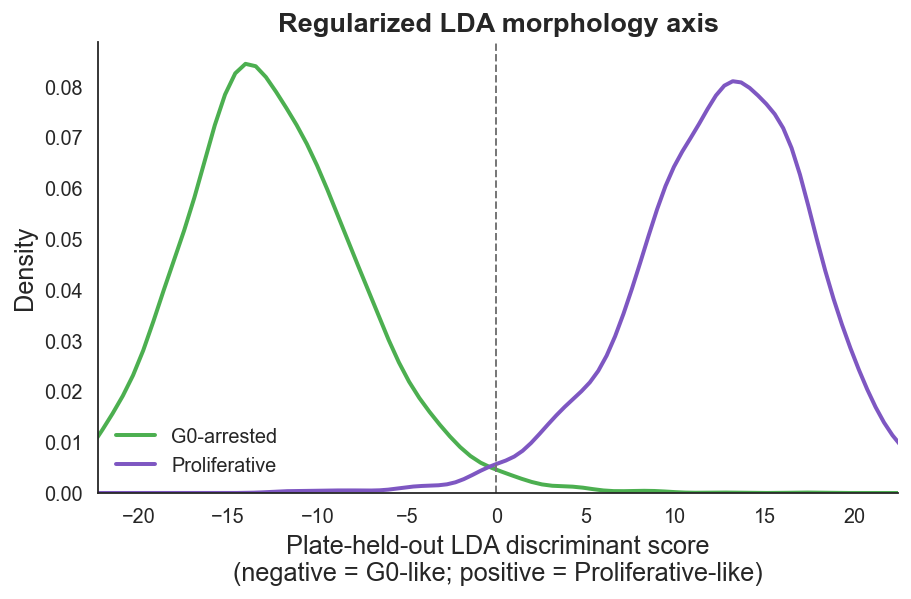

,Observed class,Cells,Median,Mean,SD
0,G0-arrested,4578,-12.923633,-12.606506,5.241406
1,Proliferative,4578,12.993727,12.606029,5.356188


In [20]:
# ---------------------------------------------------------------------
# Explicit plate-held-out LDA morphology plot
# ---------------------------------------------------------------------
required_lda_columns = {
    "Observed class",
    "Morphological discriminant score",
}

if "independent_score_table" not in globals():
    raise NameError(
        "independent_score_table was not found. Run the preceding "
        "phenotype-analysis cell first."
    )

missing_lda_columns = (
    required_lda_columns
    - set(independent_score_table.columns)
)

if missing_lda_columns:
    raise KeyError(
        "Missing columns required for the LDA plot: "
        f"{sorted(missing_lda_columns)}"
    )

lda_plot_table = independent_score_table[
    [
        "Observed class",
        "Morphological discriminant score",
    ]
].dropna().copy()

if lda_plot_table.empty:
    raise ValueError(
        "No finite plate-held-out LDA scores are available."
    )

fig, ax = plt.subplots(figsize=(7.2, 4.8))

for state, color in [
    (g0_state, G0_COLOR),
    (proliferative_state, PROLIF_COLOR),
]:
    state_scores = lda_plot_table.loc[
        lda_plot_table["Observed class"].astype(str)
        == state,
        "Morphological discriminant score",
    ]

    sns.kdeplot(
        x=state_scores,
        label=state,
        color=color,
        linewidth=2.2,
        fill=False,
        ax=ax,
    )

ax.axvline(
    0,
    color="#777777",
    linestyle="--",
    linewidth=1.1,
)

lda_plot_min, lda_plot_max = np.percentile(
    lda_plot_table[
        "Morphological discriminant score"
    ],
    [1, 99],
)

if lda_plot_min < lda_plot_max:
    ax.set_xlim(
        lda_plot_min,
        lda_plot_max,
    )

ax.set_xlabel(
    "Plate-held-out LDA discriminant score\n"
    "(negative = G0-like; positive = Proliferative-like)"
)
ax.set_ylabel("Density")
ax.set_title(
    "Regularized LDA morphology axis"
)
ax.legend(
    title="",
    frameon=False,
    fontsize=LEGEND_FONTSIZE,
    title_fontsize=LEGEND_TITLE_FONTSIZE,
)
sns.despine()
ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Supplementary_explicit_plate_held_out_LDA_morphology_axis.png",
    ),
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

lda_plot_summary = (
    lda_plot_table
    .groupby(
        "Observed class",
        observed=True,
    )["Morphological discriminant score"]
    .agg(
        Cells="size",
        Median="median",
        Mean="mean",
        SD="std",
    )
    .reset_index()
)

display(lda_plot_summary)

### Lightweight leakage audit

The time-consuming permutation analysis was removed. This section now checks only the number of cells, plates and wells per state and confirms that metadata columns are not included among the classifier features.


### Compact performance summary and prediction confidence

The summary table consolidates the main quantitative metrics. The probability plot shows the out-of-fold predicted probability for each independent profile, allowing visual inspection of classifier confidence.


In [21]:
# ---------------------------------------------------------------------
# Fast dataset-structure and classifier-feature audit
# ---------------------------------------------------------------------
dataset_structure_rows = []

for state, state_table in single_cell_df.groupby(
    STATE_COL,
    observed=True,
):
    dataset_structure_rows.append({
        "State": state,
        "Single cells": int(len(state_table)),
        "Independent plates": (
            int(state_table[PLATE_COL].nunique())
            if PLATE_COL is not None
            else np.nan
        ),
        "Independent wells": (
            int(state_table[WELL_COL].nunique())
            if WELL_COL is not None
            else np.nan
        ),
    })

dataset_structure_audit = pd.DataFrame(dataset_structure_rows)
display(dataset_structure_audit)

classifier_feature_audit = pd.DataFrame({
    "Feature": validation_features,
    "Is metadata": [
        feature.startswith("Metadata_")
        for feature in validation_features
    ],
})

if classifier_feature_audit["Is metadata"].any():
    raise ValueError(
        "Metadata columns were detected among classifier features."
    )

print(
    f"Classifier feature audit passed: "
    f"{len(validation_features)} morphological features and no metadata columns."
)

,State,Single cells,Independent plates,Independent wells
0,G0-arrested,4578,2,19
1,Proliferative,4578,2,30


Classifier feature audit passed: 488 morphological features and no metadata columns.


Permutation analysis was not run; the permutation p-value is omitted from the summary table.


,Metric,Value
0,Silhouette score (scaled features),0.049151
1,Overall single-cell mAP,0.654338
2,Single-cell LOPO balanced accuracy,0.979576
3,Single-cell LOPO ROC AUC,0.996649


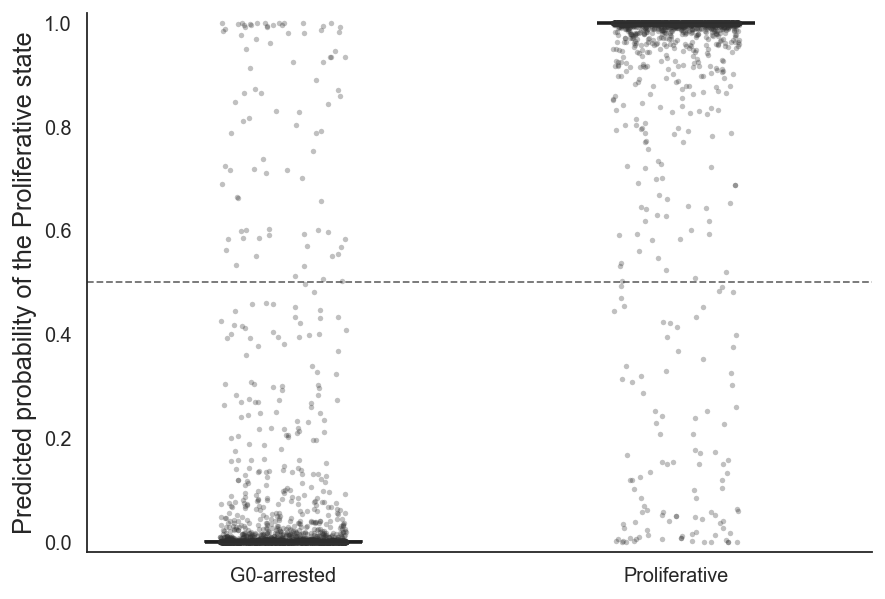

In [22]:
# ---------------------------------------------------------------------
# Compact summary table for supplementary reporting
# ---------------------------------------------------------------------
primary_silhouette = float(
    silhouette_table.loc[
        silhouette_table["Space"] == "Scaled morphological features",
        "Silhouette score",
    ].iloc[0]
)

summary_metrics = [
    "Silhouette score (scaled features)",
    "Overall single-cell mAP",
    "Single-cell LOPO balanced accuracy",
    "Single-cell LOPO ROC AUC",
]

summary_values = [
    primary_silhouette,
    overall_map,
    balanced_accuracy,
    roc_auc,
]

# Include the permutation result only when that optional analysis was run.
if "empirical_p_value" in globals():
    summary_metrics.append("Permutation p-value")
    summary_values.append(empirical_p_value)
else:
    print(
        "Permutation analysis was not run; "
        "the permutation p-value is omitted from the summary table."
    )

performance_summary = pd.DataFrame({
    "Metric": summary_metrics,
    "Value": summary_values,
})

display(performance_summary)


# ---------------------------------------------------------------------
# Out-of-fold predicted probability by observed state
# ---------------------------------------------------------------------
positive_class = label_encoder.classes_[1]

probability_plot_table = prediction_table.copy()
probability_plot_table["Observed state"] = probability_plot_table[
    "Observed class"
].astype(str)

fig, ax = plt.subplots(figsize=(7.0, 4.8))

sns.boxplot(
    data=probability_plot_table,
    x="Observed state",
    y="Predicted probability",
    order=list(label_encoder.classes_),
    hue="Observed state",
    palette={
        state: STATE_PALETTE.get(state, "#777777")
        for state in label_encoder.classes_
    },
    legend=False,
    width=0.40,
    showfliers=False,
    medianprops={
        "color": "#202020",
        "linewidth": 2.0,
    },
    ax=ax,
)

sns.stripplot(
    data=probability_plot_table,
    x="Observed state",
    y="Predicted probability",
    order=list(label_encoder.classes_),
    color="#303030",
    alpha=0.30,
    size=3,
    jitter=0.16,
    ax=ax,
)

ax.axhline(
    0.5,
    color="#707070",
    linestyle="--",
    linewidth=1.0,
)

ax.set_xlabel("")
ax.set_ylabel(
    f"Predicted probability of the {positive_class} state"
)
ax.set_ylim(-0.02, 1.02)
sns.despine()
ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

plt.tight_layout()
plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "State_classifier_predicted_probability.png",
    ),
    dpi=400,
    bbox_inches="tight",
)
plt.show()

In [23]:
# ---------------------------------------------------------------------
# Export quantitative validation results
# ---------------------------------------------------------------------
required_exports = [
    (
        silhouette_table,
        "Single_cell_silhouette_scores.csv",
    ),
    (
        correlation_table,
        "Single_cell_intra_inter_state_correlations.csv",
    ),
    (
        correlation_summary,
        "Single_cell_intra_inter_state_correlation_summary.csv",
    ),
    (
        correlation_statistics,
        "Single_cell_intra_inter_state_statistical_tests.csv",
    ),
    (
        map_table,
        "Single_cell_state_retrieval_average_precision.csv",
    ),
    (
        map_summary,
        "Single_cell_state_retrieval_mAP_summary.csv",
    ),
    (
        classifier_metrics,
        "Single_cell_classifier_metrics.csv",
    ),
    (
        fold_metrics,
        "Single_cell_classifier_fold_metrics.csv",
    ),
    (
        fold_audit,
        "Single_cell_classifier_fold_audit.csv",
    ),
    (
        prediction_table,
        "Single_cell_classifier_predictions.csv",
    ),
    (
        dataset_structure_audit,
        "Single_cell_dataset_structure_audit.csv",
    ),
    (
        classifier_feature_audit,
        "Single_cell_classifier_feature_audit.csv",
    ),
    (
        performance_summary,
        "Single_cell_performance_summary.csv",
    ),
    (
        probability_plot_table,
        "Single_cell_predicted_probability_by_state.csv",
    ),
]

for table, filename in required_exports:
    table.to_csv(
        os.path.join(OUTPUT_DIR, filename),
        index=False,
    )

# Export permutation outputs only if the optional analysis exists.
if (
    "permutation_auc_table" in globals()
    and "permutation_summary" in globals()
):
    permutation_auc_table.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "LOPO_permutation_AUC_values.csv",
        ),
        index=False,
    )

    permutation_summary.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "LOPO_permutation_test_summary.csv",
        ),
        index=False,
    )
else:
    print(
        "Optional permutation outputs were not exported "
        "because the permutation analysis was not run."
    )





# Robust morphology-based phenotypic-identity outputs
if (
    "phenotypic_identity_table" in globals()
    and "phenotypic_identity_percent" in globals()
    and "phenotypic_crossover_summary" in globals()
):
    export_tables = [
        (
            phenotypic_identity_table,
            "Single_cell_proliferative_morphology_probability_assignments.csv",
            False,
        ),
        (
            phenotypic_identity_counts,
            "Single_cell_morphological_identity_counts.csv",
            True,
        ),
        (
            phenotypic_identity_percent,
            "Single_cell_morphological_identity_percent.csv",
            True,
        ),
        (
            phenotypic_identity_ci,
            "Single_cell_morphological_identity_bootstrap_CI.csv",
            False,
        ),
        (
            phenotypic_identity_bootstrap,
            "Single_cell_morphological_identity_bootstrap_distributions.csv",
            False,
        ),
        (
            phenotypic_crossover_summary,
            "Single_cell_cross_state_crossover_summary.csv",
            False,
        ),
        (
            phenotypic_threshold_sensitivity,
            "Single_cell_cross_state_threshold_sensitivity.csv",
            False,
        ),
        (
            independent_score_table,
            "Single_cell_independent_Mahalanobis_LDA_scores.csv",
            False,
        ),
        (
            lda_plot_summary,
            "Single_cell_plate_held_out_LDA_summary.csv",
            False,
        ),
        (
            method_agreement_summary,
            "Single_cell_cross_method_agreement_summary.csv",
            False,
        ),
        (
            cross_method_table,
            "Single_cell_cross_method_continuous_scores.csv",
            False,
        ),
        (
            cross_method_correlation_summary,
            "Single_cell_cross_method_correlations.csv",
            False,
        ),
        (
            method_comparison_summary,
            "Single_cell_cross_method_quantitative_summary.csv",
            False,
        ),
        (
            calibration_table,
            "Single_cell_classifier_calibration_curve.csv",
            False,
        ),
        (
            calibration_summary,
            "Single_cell_classifier_calibration_summary.csv",
            False,
        ),
    ]

    if "phenotypic_umap_table" in globals():
        export_tables.append(
            (
                phenotypic_umap_table,
                "Single_cell_UMAP_proliferative_morphology_probability.csv",
                False,
            )
        )

    for table, filename, include_index in export_tables:
        table.to_csv(
            os.path.join(
                OUTPUT_DIR,
                filename,
            ),
            index=include_index,
        )
else:
    print(
        "Robust morphology-based phenotypic outputs were not "
        "exported because the corresponding analysis was not run."
    )

print(
    f"All available quantitative-validation outputs "
    f"were saved to: {OUTPUT_DIR}"
)

Optional permutation outputs were not exported because the permutation analysis was not run.
All available quantitative-validation outputs were saved to: /Users/thaismlacerda/Documents/single_cell_publication_outputs


## Global feature interpretation

SHAP is used only to interpret a final model fitted to the aggregated profiles after cross-validated performance has been reported. It is not used as an additional estimate of predictive performance.


In [ ]:
import re

# ---------------------------------------------------------------------
# Global SHAP interpretation at INDIVIDUAL-CELL resolution
# ---------------------------------------------------------------------
try:
    import shap

    rng_shap = np.random.default_rng(RANDOM_STATE)

    # Use a stratified cell sample for SHAP runtime, while the Random Forest
    # itself is fitted to all retained individual cells.
    shap_sample_indices = []

    for state in profile_labels.unique():
        state_indices = np.flatnonzero(
            profile_labels.to_numpy() == state
        )
        n_state_sample = min(
            max(1, MAX_SHAP_CELLS // profile_labels.nunique()),
            len(state_indices),
        )
        shap_sample_indices.extend(
            rng_shap.choice(
                state_indices,
                size=n_state_sample,
                replace=False,
            ).tolist()
        )

    single_cell_shap_model = RandomForestClassifier(
        n_estimators=500,
        class_weight="balanced_subsample",
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

    single_cell_shap_model.fit(
        single_cell_df[validation_features],
        profile_y,
    )

    shap_background = shap.sample(
        single_cell_df[validation_features],
        min(500, len(single_cell_df)),
        random_state=RANDOM_STATE,
    )

    shap_explained_cells = (
        single_cell_df
        .iloc[shap_sample_indices][validation_features]
        .copy()
    )

    explainer = shap.TreeExplainer(
        single_cell_shap_model,
        data=shap_background,
        feature_perturbation="interventional",
    )

    shap_values_raw = explainer.shap_values(
        shap_explained_cells,
        check_additivity=False,
    )

    # Select the positive class consistently.
    if isinstance(shap_values_raw, list):
        shap_array = np.asarray(shap_values_raw[-1])
    else:
        shap_values_raw = np.asarray(shap_values_raw)
        if shap_values_raw.ndim == 3:
            shap_array = shap_values_raw[:, :, 1]
        else:
            shap_array = shap_values_raw

    shap_importance = (
        pd.DataFrame({
            "Feature": validation_features,
            "Mean absolute SHAP": np.abs(shap_array).mean(axis=0),
        })
        .sort_values(
            "Mean absolute SHAP",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    top_shap_features = shap_importance.head(10)
    display(top_shap_features)

    top_names = top_shap_features["Feature"].tolist()
    top_indices = [
        validation_features.index(name)
        for name in top_names
    ]

    def shorten_feature_name(feature_name):
        replacements = {
            "Nuclei_": "Nuclei: ",
            "Cells_": "Cells: ",
            "Cytoplasm_": "Cytoplasm: ",
            "AreaShape_": "",
            "Intensity_": "Intensity ",
            "Texture_Correlation_": "Texture corr ",
            "Granularity_": "Granularity ",
            "RadialDistribution_MeanFrac_": "Radial mean frac ",
            "MassDisplacement_": "Mass displacement ",
            "AOGFP": "AO-GFP",
            "AOPI": "AO-PI",
        }

        shortened = feature_name
        for old_text, new_text in replacements.items():
            shortened = shortened.replace(old_text, new_text)

        shortened = shortened.replace("__", "_")
        shortened = shortened.replace("_", " ")
        shortened = re.sub(r"\s+", " ", shortened).strip()

        if len(shortened) > 42:
            shortened = shortened[:39].rstrip() + "..."

        return shortened

    shap_display_names = [
        shorten_feature_name(name)
        for name in top_names
    ]

    shap_label_table = pd.DataFrame({
        "Full feature name": top_names,
        "Figure label": shap_display_names,
    })
    display(shap_label_table)

    plt.figure(figsize=(10.5, 6.8))
    shap.summary_plot(
        shap_array[:, top_indices],
        shap_explained_cells.iloc[:, top_indices],
        feature_names=shap_display_names,
        show=False,
        plot_type="dot",
        plot_size=None,
    )
    plt.xlabel("SHAP value", fontsize=HEATMAP_ANNOT_FONTSIZE)
    plt.xticks(fontsize=TICK_FONTSIZE)
    plt.yticks(fontsize=TICK_FONTSIZE)
    plt.tight_layout()
    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "Single_cell_RandomForest_SHAP_summary_top10.png",
        ),
        dpi=400,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()

    shap_importance.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Single_cell_RandomForest_SHAP_feature_importance.csv",
        ),
        index=False,
    )

    shap_label_table.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Single_cell_SHAP_figure_label_mapping.csv",
        ),
        index=False,
    )

    pd.DataFrame({
        "Single-cell row index": shap_sample_indices,
        "State": profile_labels.iloc[shap_sample_indices].to_numpy(),
    }).to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Single_cell_SHAP_sample_metadata.csv",
        ),
        index=False,
    )

except ImportError:
    print(
        "SHAP is not installed. Single-cell classification remains valid; "
        "only the optional Random Forest SHAP analysis was skipped."
    )

 17%|===                 | 693/4000 [01:05<05:10]       